<a href="https://colab.research.google.com/github/carolinammatos/streaming_churn/blob/master/M%C3%B3dulo_3_AN%C3%81LISE_UNIVARIADA_E_BIVARIADA_E_FRAMEWORKS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Carregar dados do Google Drive

In [48]:
from google.colab import drive
import pandas as pd
import os

# Montar o Google Drive
drive.mount('/content/drive')

# Caminho do arquivo no Drive
caminho_pasta = '/content/drive/MyDrive/Pós_graduação/Módulo_3'
caminho_arquivo = os.path.join(caminho_pasta, 'clientes_base.csv')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


##Carregamento do dataset

In [49]:
# Carregar o DataFrame de forma segura com tratamento de erro
try:
    df = pd.read_csv(caminho_arquivo)
    print('Arquivo carregado com sucesso!')
except FileNotFoundError:
    print(f'Erro: Arquivo não encontrado no caminho: {caminho_arquivo}')

# Exibir as primeiras 5 linhas do DataFrame se ele foi carregado com sucesso
if 'df' in locals() or 'df' in globals():
    print('Primeiras 5 linhas do DataFrame:')
    display(df.head())

    # Exibir as informações do DataFrame, incluindo os tipos das colunas
    print('\nDataFrame Info (column types and non-null counts):')
    df.info()

Arquivo carregado com sucesso!
Primeiras 5 linhas do DataFrame:


,cliente_id,idade,plano,ciclo,valor_mensal,regiao,canal_aquisicao,nps,data_assinatura,data_cancelamento,data_ultimo_acesso,data_extracao,dias_ativos_ult_mes,horas_assistidas_total,motivo_cancelamento,churn
0,5746,36,BASICO,Anual,19.9,Sudeste,Indicacao,6,2023-04-11,NaN,2024-01-29,2024-01-31,15,276.0,NaN,0
1,4100,48,Padrão,Mensal,34.9,Sudeste,orgânico,8,2022-06-02,NaN,2024-01-30,2024-01-31,14,394.9,NaN,0
2,4690,48,Premium,Mensal,55.9,Nordeste,orgânico,4,2021-03-20,2022-11-17,2022-10-31,2024-01-31,5,257.0,PREÇO,1
3,3454,46,BASICO,Anual,1990.0,Sul,Google,10,2023-04-02,NaN,2024-01-13,2024-01-31,19,385.0,NaN,0
4,1437,46,Basico,Mensal,19.9,Norte,indicação,8,2023-04-21,NaN,2024-01-16,2024-01-31,11,205.3,NaN,0



DataFrame Info (column types and non-null counts):
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5025 entries, 0 to 5024
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   cliente_id              5025 non-null   int64  
 1   idade                   5025 non-null   int64  
 2   plano                   5025 non-null   object 
 3   ciclo                   5025 non-null   object 
 4   valor_mensal            5025 non-null   float64
 5   regiao                  5025 non-null   object 
 6   canal_aquisicao         5025 non-null   object 
 7   nps                     5025 non-null   int64  
 8   data_assinatura         5025 non-null   object 
 9   data_cancelamento       1516 non-null   object 
 10  data_ultimo_acesso      4975 non-null   object 
 11  data_extracao           5025 non-null   object 
 12  dias_ativos_ult_mes     5025 non-null   int64  
 13  horas_assistidas_total  5025 non-null   f

# **ANÁLISE UNIVARIADA**

##Análise de colunas categóricas


=== Análise da Coluna: plano ===


,count
plano,
Basico,708
BASICO,677
básico,677
Padrao,665
Padrão,654
padrão,646
premium,513
Premium,485


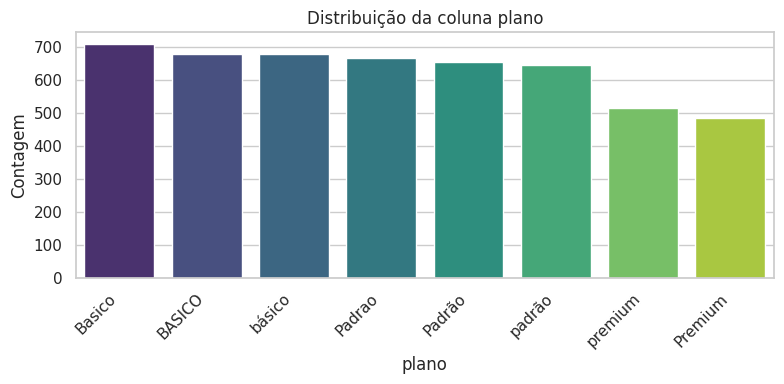


=== Análise da Coluna: ciclo ===


,count
ciclo,
Mensal,3794
Anual,1231


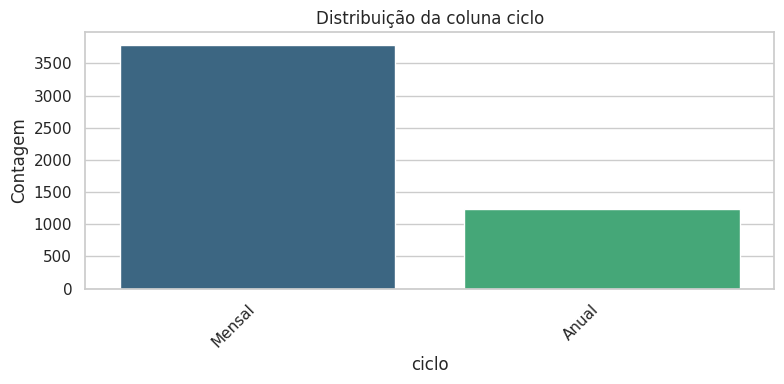


=== Análise da Coluna: regiao ===


,count
regiao,
Sudeste,2057
Nordeste,964
Sul,938
Centro-Oeste,488
Norte,408
?,170


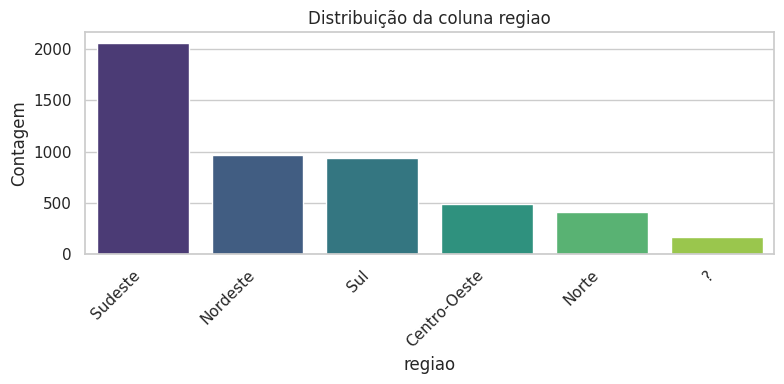


=== Análise da Coluna: canal_aquisicao ===


,count
canal_aquisicao,
Organico,781
orgânico,729
Indicacao,556
IG,529
indicação,526
Instagram,519
instagram,499
Google,452
google,434


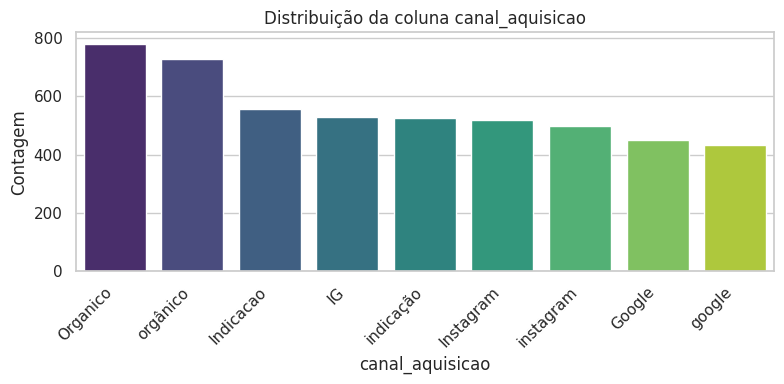

In [50]:
import matplotlib.pyplot as plt
import seaborn as sns

# Lista de colunas a serem analisadas
colunas = ['plano', 'ciclo', 'regiao', 'canal_aquisicao']

# Configuração do estilo dos gráficos
sns.set_theme(style="whitegrid")

# Analisar cada coluna
for col in colunas:
    print(f"\n=== Análise da Coluna: {col} ===")

    # Contagem de valores únicos
    contagem = df[col].value_counts()
    display(contagem.to_frame())

    # Criar o gráfico de barras
    plt.figure(figsize=(8, 4))
    sns.barplot(x=contagem.index, y=contagem.values, palette='viridis', hue=contagem.index, legend=False)
    plt.title(f'Distribuição da coluna {col}')
    plt.xlabel(col)
    plt.ylabel('Contagem')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

##Análise de Nulos e Limpeza de Dados

In [51]:
# 1- Quantos nulos tem nas colunas?
print("=== 1. Quantidade de valores nulos por coluna ===")
nulos_por_coluna = df.isnull().sum()
display(nulos_por_coluna.to_frame(name='Nulos'))

# 2- Mostre um exemplo do dataframe para quando a coluna região é "?"
print("\n=== 2. Exemplo do DataFrame com região sendo '?' ===")
exemplo_regiao_interrogacao = df[df['regiao'] == '?']
display(exemplo_regiao_interrogacao.head())

# 3- Para coluna plano, substitui:
# Basico, BASICO para básico
# Padrao, Padrão para padrão
# Premium para premium
print("\n=== 3. Padronizando a coluna 'plano' ===")
print("Valores antes:", df['plano'].unique())

mapeamento_plano = {
    'Basico': 'básico',
    'BASICO': 'básico',
    'básico': 'básico',
    'Padrao': 'padrão',
    'Padrão': 'padrão',
    'padrão': 'padrão',
    'Premium': 'premium',
    'premium': 'premium'
}
df['plano'] = df['plano'].map(mapeamento_plano)
print("Valores depois:", df['plano'].unique())

# 4- Para a coluna canal_aquisicao, substitui:
# Organico para orgânico
# Indicacao para indicação
# IG, Instagram para instagram
# Google para google
print("\n=== 4. Padronizando a coluna 'canal_aquisicao' ===")
print("Valores antes:", df['canal_aquisicao'].unique())

mapeamento_canal = {
    'Organico': 'orgânico',
    'orgânico': 'orgânico',
    'Indicacao': 'indicação',
    'indicação': 'indicação',
    'IG': 'instagram',
    'Instagram': 'instagram',
    'instagram': 'instagram',
    'Google': 'google',
    'google': 'google'
}
df['canal_aquisicao'] = df['canal_aquisicao'].map(mapeamento_canal)
print("Valores depois:", df['canal_aquisicao'].unique())

=== 1. Quantidade de valores nulos por coluna ===


,Nulos
cliente_id,0
idade,0
plano,0
ciclo,0
valor_mensal,0
regiao,0
canal_aquisicao,0
nps,0
data_assinatura,0
data_cancelamento,3509



=== 2. Exemplo do DataFrame com região sendo '?' ===


,cliente_id,idade,plano,ciclo,valor_mensal,regiao,canal_aquisicao,nps,data_assinatura,data_cancelamento,data_ultimo_acesso,data_extracao,dias_ativos_ult_mes,horas_assistidas_total,motivo_cancelamento,churn
6,4918,37,Basico,Mensal,19.9,?,instagram,4,2023-10-12,2023-12-28,2023-12-09,2024-01-31,5,29.6,problema tecnico,1
10,4356,30,básico,Mensal,19.9,?,Organico,8,2020-12-22,NaN,2024-01-11,2024-01-31,15,900.0,NaN,0
34,1433,56,Padrão,Anual,3490.0,?,orgânico,9,2023-04-14,NaN,2024-01-22,2024-01-31,11,180.4,NaN,0
68,5259,41,padrão,Mensal,34.9,?,google,5,2023-05-03,NaN,2024-01-28,2024-01-31,8,139.9,NaN,0
135,2171,42,Padrão,Mensal,3490.0,?,orgânico,10,2021-04-16,NaN,2024-01-06,2024-01-31,10,505.2,NaN,0



=== 3. Padronizando a coluna 'plano' ===
Valores antes: ['BASICO' 'Padrão' 'Premium' 'Basico' 'premium' 'básico' 'Padrao' 'padrão']
Valores depois: ['básico' 'padrão' 'premium']

=== 4. Padronizando a coluna 'canal_aquisicao' ===
Valores antes: ['Indicacao' 'orgânico' 'Google' 'indicação' 'Organico' 'instagram' 'IG'
 'google' 'Instagram']
Valores depois: ['indicação' 'orgânico' 'google' 'instagram']



=== Distribuição Atualizada: plano ===


,count
plano,
básico,2062
padrão,1965
premium,998


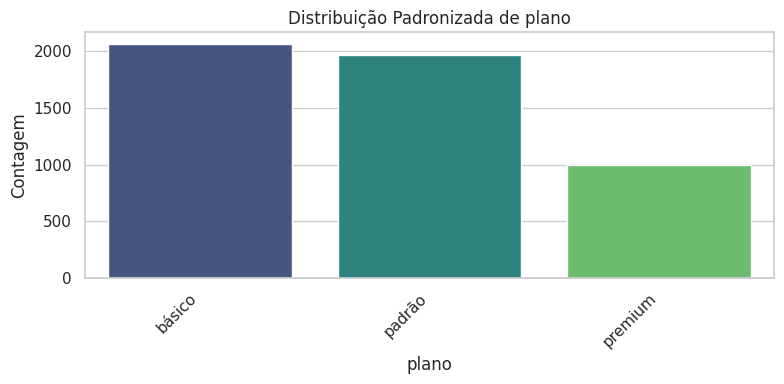


=== Distribuição Atualizada: canal_aquisicao ===


,count
canal_aquisicao,
instagram,1547
orgânico,1510
indicação,1082
google,886


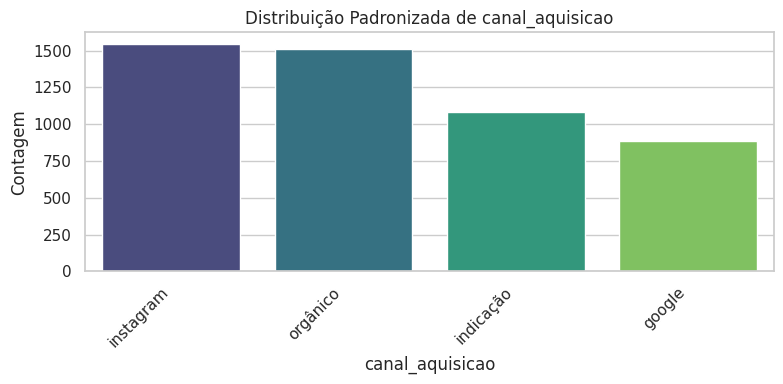

In [52]:
import matplotlib.pyplot as plt
import seaborn as sns

# Definindo as colunas limpas para plotagem
colunas_limpas = ['plano', 'canal_aquisicao']

sns.set_theme(style="whitegrid")

for col in colunas_limpas:
    print(f"\n=== Distribuição Atualizada: {col} ===")
    contagem = df[col].value_counts()
    display(contagem.to_frame())

    plt.figure(figsize=(8, 4))
    sns.barplot(x=contagem.index, y=contagem.values, palette='viridis', hue=contagem.index, legend=False)
    plt.title(f'Distribuição Padronizada de {col}')
    plt.xlabel(col)
    plt.ylabel('Contagem')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

##Tratamento de Valores '?'

In [53]:
import numpy as np

# Substituir '?' por NaN (nulo) em todo o DataFrame
df = df.replace('?', np.nan)

print("=== Substituição concluída! ===")
# Verificar a nova contagem de nulos nas colunas para validar a substituição
nulos_atualizados = df.isnull().sum()
display(nulos_atualizados.to_frame(name='Nulos Atuais'))

=== Substituição concluída! ===


,Nulos Atuais
cliente_id,0
idade,0
plano,0
ciclo,0
valor_mensal,0
regiao,170
canal_aquisicao,0
nps,0
data_assinatura,0
data_cancelamento,3509


##Conversão de Colunas de Data para Datetime

In [54]:
# Identificar as colunas que representam datas
colunas_datas = ['data_assinatura', 'data_cancelamento', 'data_ultimo_acesso', 'data_extracao']

# Converter as colunas para o tipo datetime
for col in colunas_datas:
    df[col] = pd.to_datetime(df[col], errors='coerce')

print("=== Conversão concluída com sucesso! ===")
# Exibir os tipos de dados atualizados
df.info()

=== Conversão concluída com sucesso! ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5025 entries, 0 to 5024
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   cliente_id              5025 non-null   int64         
 1   idade                   5025 non-null   int64         
 2   plano                   5025 non-null   object        
 3   ciclo                   5025 non-null   object        
 4   valor_mensal            5025 non-null   float64       
 5   regiao                  4855 non-null   object        
 6   canal_aquisicao         5025 non-null   object        
 7   nps                     5025 non-null   int64         
 8   data_assinatura         5025 non-null   datetime64[ns]
 9   data_cancelamento       1516 non-null   datetime64[ns]
 10  data_ultimo_acesso      4975 non-null   datetime64[ns]
 11  data_extracao           5025 non-null   datetime64[ns]
 12  dias_at

##Criação de Colunas de Diferença de Datas

In [55]:
# Criando as diferenças respeitando a ordem cronológica esperada (sem .abs())
# Ordem: Data Posterior esperada - Data Anterior esperada

df['diff_data_assinatura_vs_data_cancelamento_dias'] = (df['data_cancelamento'] - df['data_assinatura']).dt.days
df['diff_data_assinatura_vs_data_ultimo_acesso_dias'] = (df['data_ultimo_acesso'] - df['data_assinatura']).dt.days
df['diff_data_assinatura_vs_data_extracao_dias'] = (df['data_extracao'] - df['data_assinatura']).dt.days

# Esta diferença deve ser idealmente negativa ou zero (último acesso ocorre antes ou no dia do cancelamento)
df['diff_data_cancelamento_vs_data_ultimo_acesso_dias'] = (df['data_ultimo_acesso'] - df['data_cancelamento']).dt.days

df['diff_data_cancelamento_vs_data_extracao_dias'] = (df['data_extracao'] - df['data_cancelamento']).dt.days
df['diff_data_ultimo_acesso_vs_data_extracao_dias'] = (df['data_extracao'] - df['data_ultimo_acesso']).dt.days

print("=== Novas colunas de diferença calculadas sem o uso de .abs()! ===")
colunas_novas = [c for c in df.columns if c.startswith('diff_data_')]
display(df[colunas_datas + colunas_novas].head())

=== Novas colunas de diferença calculadas sem o uso de .abs()! ===


,data_assinatura,data_cancelamento,data_ultimo_acesso,data_extracao,diff_data_assinatura_vs_data_cancelamento_dias,diff_data_assinatura_vs_data_ultimo_acesso_dias,diff_data_assinatura_vs_data_extracao_dias,diff_data_cancelamento_vs_data_ultimo_acesso_dias,diff_data_cancelamento_vs_data_extracao_dias,diff_data_ultimo_acesso_vs_data_extracao_dias
0,2023-04-11,NaT,2024-01-29,2024-01-31,NaN,293.0,295,NaN,NaN,2.0
1,2022-06-02,NaT,2024-01-30,2024-01-31,NaN,607.0,608,NaN,NaN,1.0
2,2021-03-20,2022-11-17,2022-10-31,2024-01-31,607.0,590.0,1047,-17.0,440.0,457.0
3,2023-04-02,NaT,2024-01-13,2024-01-31,NaN,286.0,304,NaN,NaN,18.0
4,2023-04-21,NaT,2024-01-16,2024-01-31,NaN,270.0,285,NaN,NaN,15.0


##Sanity Check nas Colunas de Diferença de Datas

In [56]:
print("=== 1. Estatísticas Descritivas das Diferenças Direcionais ===")
display(df[colunas_novas].describe())

print("\n=== 2. Análise de Inconsistências (Valores Negativos Inesperados) ===")
# - Assinatura vs Cancelamento: não deve ser negativo (cancelamento não ocorre antes da assinatura)
# - Assinatura vs Último Acesso: não deve ser negativo (último acesso não ocorre antes da assinatura)
# - Assinatura vs Extração: não deve ser negativo
# - Cancelamento vs Último Acesso: DEVE ser majoritariamente negativo ou zero (último acesso antes do cancelamento)

valores_negativos = (df[colunas_novas] < 0).sum().to_frame(name='Qtd Valores Negativos')
display(valores_negativos)

# Verificar se alguém acessou o sistema APÓS o cancelamento
acessos_apos_cancelamento = df[df['diff_data_cancelamento_vs_data_ultimo_acesso_dias'] > 0]
print(f"\nQuantidade de clientes com acessos APÓS o cancelamento: {len(acessos_apos_cancelamento)}")
if len(acessos_apos_cancelamento) > 0:
    display(acessos_apos_cancelamento[['cliente_id', 'data_assinatura', 'data_cancelamento', 'data_ultimo_acesso', 'diff_data_cancelamento_vs_data_ultimo_acesso_dias']].head())

print("\n=== 3. Valores Nulos nas Diferenças ===")
# Naturalmente haverá nulos onde 'data_cancelamento' ou 'data_ultimo_acesso' originalmente eram nulas
display(df[colunas_novas].isnull().sum().to_frame(name='Qtd Nulos'))

=== 1. Estatísticas Descritivas das Diferenças Direcionais ===


,diff_data_assinatura_vs_data_cancelamento_dias,diff_data_assinatura_vs_data_ultimo_acesso_dias,diff_data_assinatura_vs_data_extracao_dias,diff_data_cancelamento_vs_data_ultimo_acesso_dias,diff_data_cancelamento_vs_data_extracao_dias,diff_data_ultimo_acesso_vs_data_extracao_dias
count,1516.000000,4975.000000,5025.000000,1501.000000,1516.000000,4975.000000
mean,220.407652,372.186533,412.432040,-21.000666,79.694591,40.451859
std,145.004268,277.107592,270.382969,10.783104,67.851077,55.107192
min,11.000000,-47.000000,1.000000,-137.000000,3.000000,0.000000
25%,118.000000,163.000000,213.000000,-30.000000,30.000000,10.000000
50%,182.500000,307.000000,349.000000,-21.000000,60.500000,20.000000
75%,288.500000,512.000000,549.000000,-12.000000,107.250000,44.000000
max,1067.000000,1809.000000,1815.000000,-3.000000,440.000000,469.000000



=== 2. Análise de Inconsistências (Valores Negativos Inesperados) ===


,Qtd Valores Negativos
diff_data_assinatura_vs_data_cancelamento_dias,0
diff_data_assinatura_vs_data_ultimo_acesso_dias,1
diff_data_assinatura_vs_data_extracao_dias,0
diff_data_cancelamento_vs_data_ultimo_acesso_dias,1501
diff_data_cancelamento_vs_data_extracao_dias,0
diff_data_ultimo_acesso_vs_data_extracao_dias,0



Quantidade de clientes com acessos APÓS o cancelamento: 0

=== 3. Valores Nulos nas Diferenças ===


,Qtd Nulos
diff_data_assinatura_vs_data_cancelamento_dias,3509
diff_data_assinatura_vs_data_ultimo_acesso_dias,50
diff_data_assinatura_vs_data_extracao_dias,0
diff_data_cancelamento_vs_data_ultimo_acesso_dias,3524
diff_data_cancelamento_vs_data_extracao_dias,3509
diff_data_ultimo_acesso_vs_data_extracao_dias,50


##Verificação após o filtro

In [57]:
# 1. Identificar e listar as colunas numéricas (tipos int e float)
colunas_numericas = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
print("=== Lista de Colunas Numéricas ===")
print(colunas_numericas)

# 2. Retornar as estatísticas descritivas das colunas numéricas
print("\n=== Estatísticas Descritivas das Colunas Numéricas ===")
display(df[colunas_numericas].describe())

# 3. Retornar a quantidade de valores nulos em cada coluna numérica
print("\n=== Quantidade de Nulos nas Colunas Numéricas ===")
nulos_numericas = df[colunas_numericas].isnull().sum().to_frame(name='Qtd Nulos')
display(nulos_numericas)

=== Lista de Colunas Numéricas ===
['cliente_id', 'idade', 'valor_mensal', 'nps', 'dias_ativos_ult_mes', 'horas_assistidas_total', 'churn', 'diff_data_assinatura_vs_data_cancelamento_dias', 'diff_data_assinatura_vs_data_ultimo_acesso_dias', 'diff_data_assinatura_vs_data_extracao_dias', 'diff_data_cancelamento_vs_data_ultimo_acesso_dias', 'diff_data_cancelamento_vs_data_extracao_dias', 'diff_data_ultimo_acesso_vs_data_extracao_dias']

=== Estatísticas Descritivas das Colunas Numéricas ===


,cliente_id,idade,valor_mensal,nps,dias_ativos_ult_mes,horas_assistidas_total,churn,diff_data_assinatura_vs_data_cancelamento_dias,diff_data_assinatura_vs_data_ultimo_acesso_dias,diff_data_assinatura_vs_data_extracao_dias,diff_data_cancelamento_vs_data_ultimo_acesso_dias,diff_data_cancelamento_vs_data_extracao_dias,diff_data_ultimo_acesso_vs_data_extracao_dias
count,5025.000000,5025.000000,5025.00000,5025.000000,5025.000000,5025.000000,5025.000000,1516.000000,4975.000000,5025.000000,1501.000000,1516.000000,4975.000000
mean,3497.592438,36.329154,416.08394,6.409751,10.653731,281.856796,0.301692,220.407652,372.186533,412.432040,-21.000666,79.694591,40.451859
std,1443.146051,11.678632,1127.94888,2.435118,6.000091,254.707091,0.459038,145.004268,277.107592,270.382969,10.783104,67.851077,55.107192
min,1000.000000,-2.000000,19.90000,0.000000,0.000000,0.000000,0.000000,11.000000,-47.000000,1.000000,-137.000000,3.000000,0.000000
25%,2248.000000,29.000000,19.90000,5.000000,5.000000,65.400000,0.000000,118.000000,163.000000,213.000000,-30.000000,30.000000,10.000000
50%,3496.000000,36.000000,34.90000,7.000000,12.000000,208.600000,0.000000,182.500000,307.000000,349.000000,-21.000000,60.500000,20.000000
75%,4747.000000,44.000000,55.90000,8.000000,15.000000,427.700000,1.000000,288.500000,512.000000,549.000000,-12.000000,107.250000,44.000000
max,5999.000000,300.000000,5590.00000,10.000000,28.000000,900.000000,1.000000,1067.000000,1809.000000,1815.000000,-3.000000,440.000000,469.000000



=== Quantidade de Nulos nas Colunas Numéricas ===


,Qtd Nulos
cliente_id,0
idade,0
valor_mensal,0
nps,0
dias_ativos_ult_mes,0
horas_assistidas_total,0
churn,0
diff_data_assinatura_vs_data_cancelamento_dias,3509
diff_data_assinatura_vs_data_ultimo_acesso_dias,50
diff_data_assinatura_vs_data_extracao_dias,0


In [58]:
# 1. Armazenar a quantidade de linhas antes do filtro
linhas_antes = df.shape[0]

# 2. Aplicar o filtro: valor >= 0 OU valor é nulo
filtro = (df['diff_data_assinatura_vs_data_ultimo_acesso_dias'] >= 0) | (df['diff_data_assinatura_vs_data_ultimo_acesso_dias'].isnull())
df_filtrado = df[filtro].copy()

# 3. Calcular a diferença
linhas_depois = df_filtrado.shape[0]
linhas_removidas = linhas_antes - linhas_depois

print("=== Etapa 9: Filtragem do Dataset ===")
print(f"Linhas antes do filtro: {linhas_antes}")
print(f"Linhas após o filtro: {linhas_depois}")
print(f"Linhas inconsistentes removidas (onde a diferença era negativa): {linhas_removidas}")

# Opcional: Se quiser sobrescrever o df original com o df filtrado para as próximas etapas:
# df = df_filtrado

=== Etapa 9: Filtragem do Dataset ===
Linhas antes do filtro: 5025
Linhas após o filtro: 5024
Linhas inconsistentes removidas (onde a diferença era negativa): 1


##Verificação após o filtro

In [65]:
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns

print("Colunas Numéricas e suas Estatísticas Descritivas:")
display(df[numerical_cols].describe())

print("\nQuantidade de Valores Nulos nas Colunas Numéricas:")
display(df[numerical_cols].isnull().sum())

Colunas Numéricas e suas Estatísticas Descritivas:


,cliente_id,idade,valor_mensal,nps,dias_ativos_ult_mes,horas_assistidas_total,churn,diff_data_assinatura_vs_data_cancelamento_dias,diff_data_assinatura_vs_data_ultimo_acesso_dias,diff_data_assinatura_vs_data_extracao_dias,diff_data_cancelamento_vs_data_ultimo_acesso_dias,diff_data_cancelamento_vs_data_extracao_dias,diff_data_ultimo_acesso_vs_data_extracao_dias,recencia,meses_assinatura,receita_acumulada
count,5025.000000,5025.000000,5025.00000,5025.000000,5025.000000,5025.000000,5025.000000,1516.000000,4975.000000,5025.000000,1501.000000,1516.000000,4975.000000,4975.000000,5025.000000,5025.000000
mean,3497.592438,36.329154,416.08394,6.409751,10.653731,281.856796,0.301692,220.407652,372.186533,412.432040,-21.000666,79.694591,40.451859,40.451859,12.946295,5401.234112
std,1443.146051,11.678632,1127.94888,2.435118,6.000091,254.707091,0.459038,145.004268,277.107592,270.382969,10.783104,67.851077,55.107192,55.107192,9.180908,18440.216031
min,1000.000000,-2.000000,19.90000,0.000000,0.000000,0.000000,0.000000,11.000000,-47.000000,1.000000,-137.000000,3.000000,0.000000,0.000000,0.033333,0.663333
25%,2248.000000,29.000000,19.90000,5.000000,5.000000,65.400000,0.000000,118.000000,163.000000,213.000000,-30.000000,30.000000,10.000000,10.000000,6.033333,187.296667
50%,3496.000000,36.000000,34.90000,7.000000,12.000000,208.600000,0.000000,182.500000,307.000000,349.000000,-21.000000,60.500000,20.000000,20.000000,10.766667,374.593333
75%,4747.000000,44.000000,55.90000,8.000000,15.000000,427.700000,1.000000,288.500000,512.000000,549.000000,-12.000000,107.250000,44.000000,44.000000,17.600000,758.493333
max,5999.000000,300.000000,5590.00000,10.000000,28.000000,900.000000,1.000000,1067.000000,1809.000000,1815.000000,-3.000000,440.000000,469.000000,469.000000,60.500000,289375.666667



Quantidade de Valores Nulos nas Colunas Numéricas:


,0
cliente_id,0
idade,0
valor_mensal,0
nps,0
dias_ativos_ult_mes,0
horas_assistidas_total,0
churn,0
diff_data_assinatura_vs_data_cancelamento_dias,3509
diff_data_assinatura_vs_data_ultimo_acesso_dias,50
diff_data_assinatura_vs_data_extracao_dias,0


In [66]:
df.isnull().sum()

,0
cliente_id,0
idade,0
plano,0
ciclo,0
valor_mensal,0
regiao,170
canal_aquisicao,0
nps,0
data_assinatura,0
data_cancelamento,3509


In [68]:
# Criar um novo DataFrame filtrando as linhas conforme a condição (corrigido com o nome exato da coluna)
df_filtrado = df[df['diff_data_assinatura_vs_data_ultimo_acesso_dias'].isnull() | (df['diff_data_assinatura_vs_data_ultimo_acesso_dias'] >= 0)].copy()

print("Primeiras 5 linhas do novo DataFrame filtrado:")
display(df_filtrado.head())

print(f"\nNúmero de linhas no DataFrame original: {len(df)}")
print(f"Número de linhas no DataFrame filtrado: {len(df_filtrado)}")

Primeiras 5 linhas do novo DataFrame filtrado:


,cliente_id,idade,plano,ciclo,valor_mensal,regiao,canal_aquisicao,nps,data_assinatura,data_cancelamento,...,churn,diff_data_assinatura_vs_data_cancelamento_dias,diff_data_assinatura_vs_data_ultimo_acesso_dias,diff_data_assinatura_vs_data_extracao_dias,diff_data_cancelamento_vs_data_ultimo_acesso_dias,diff_data_cancelamento_vs_data_extracao_dias,diff_data_ultimo_acesso_vs_data_extracao_dias,recencia,meses_assinatura,receita_acumulada
0,5746,36,básico,Anual,19.9,Sudeste,indicação,6,2023-04-11,NaT,...,0,NaN,293.0,295,NaN,NaN,2.0,2.0,9.833333,195.683333
1,4100,48,padrão,Mensal,34.9,Sudeste,orgânico,8,2022-06-02,NaT,...,0,NaN,607.0,608,NaN,NaN,1.0,1.0,20.266667,707.306667
2,4690,48,premium,Mensal,55.9,Nordeste,orgânico,4,2021-03-20,2022-11-17,...,1,607.0,590.0,1047,-17.0,440.0,457.0,457.0,20.233333,1131.043333
3,3454,46,básico,Anual,1990.0,Sul,google,10,2023-04-02,NaT,...,0,NaN,286.0,304,NaN,NaN,18.0,18.0,10.133333,20165.333333
4,1437,46,básico,Mensal,19.9,Norte,indicação,8,2023-04-21,NaT,...,0,NaN,270.0,285,NaN,NaN,15.0,15.0,9.500000,189.050000



Número de linhas no DataFrame original: 5025
Número de linhas no DataFrame filtrado: 5024


##Colunas numéricas

In [69]:
df_filtrado.describe()

,cliente_id,idade,valor_mensal,nps,data_assinatura,data_cancelamento,data_ultimo_acesso,data_extracao,dias_ativos_ult_mes,horas_assistidas_total,churn,diff_data_assinatura_vs_data_cancelamento_dias,diff_data_assinatura_vs_data_ultimo_acesso_dias,diff_data_assinatura_vs_data_extracao_dias,diff_data_cancelamento_vs_data_ultimo_acesso_dias,diff_data_cancelamento_vs_data_extracao_dias,diff_data_ultimo_acesso_vs_data_extracao_dias,recencia,meses_assinatura,receita_acumulada
count,5024.000000,5024.000000,5024.000000,5024.000000,5024,1515,4974,5024,5024.000000,5024.000000,5024.000000,1515.000000,4974.000000,5024.000000,1500.000000,1515.000000,4974.000000,4974.000000,5024.000000,5024.000000
mean,3497.606688,36.326831,416.155633,6.410032,2022-12-14 12:27:13.757961728,2023-11-12 07:16:16.633663232,2023-12-21 13:59:16.574185472,2024-01-31 00:00:00,10.655454,281.909514,0.301553,220.493729,372.270808,412.481091,-20.923333,79.697030,40.417169,40.417169,12.948275,5402.275819
min,1000.000000,-2.000000,19.900000,0.000000,2019-02-11 00:00:00,2022-11-17 00:00:00,2022-10-19 00:00:00,2024-01-31 00:00:00,0.000000,0.000000,0.000000,11.000000,0.000000,1.000000,-39.000000,3.000000,0.000000,0.000000,0.033333,0.663333
25%,2247.750000,29.000000,19.900000,5.000000,2022-07-30 18:00:00,2023-10-15 12:00:00,2023-12-18 00:00:00,2024-01-31 00:00:00,5.000000,65.475000,0.000000,118.000000,163.000000,213.000000,-30.000000,30.000000,10.000000,10.000000,6.033333,187.296667
50%,3496.500000,36.000000,34.900000,7.000000,2023-02-16 00:00:00,2023-12-02 00:00:00,2024-01-11 00:00:00,2024-01-31 00:00:00,12.000000,208.700000,0.000000,183.000000,307.000000,349.000000,-21.000000,60.000000,20.000000,20.000000,10.783333,374.593333
75%,4747.250000,44.000000,55.900000,8.000000,2023-07-02 00:00:00,2024-01-01 00:00:00,2024-01-21 00:00:00,2024-01-31 00:00:00,15.000000,427.750000,1.000000,289.000000,512.000000,549.250000,-12.000000,107.500000,44.000000,44.000000,17.600000,758.749167
max,5999.000000,300.000000,5590.000000,10.000000,2024-01-30 00:00:00,2024-01-28 00:00:00,2024-01-31 00:00:00,2024-01-31 00:00:00,28.000000,900.000000,1.000000,1067.000000,1809.000000,1815.000000,-3.000000,440.000000,469.000000,469.000000,60.500000,289375.666667
std,1443.289344,11.678633,1128.049703,2.435279,NaN,NaN,NaN,NaN,5.999446,254.705024,0.458978,145.013398,277.071683,270.387522,10.361967,67.873415,55.058380,55.058380,9.180749,18441.903649


Gerando boxplots e histogramas para as seguintes colunas numéricas: ['idade', 'valor_mensal', 'nps', 'dias_ativos_ult_mes', 'horas_assistidas_total', 'churn', 'diff_data_assinatura_vs_data_cancelamento_dias', 'diff_data_assinatura_vs_data_ultimo_acesso_dias', 'diff_data_assinatura_vs_data_extracao_dias', 'diff_data_cancelamento_vs_data_ultimo_acesso_dias', 'diff_data_cancelamento_vs_data_extracao_dias', 'diff_data_ultimo_acesso_vs_data_extracao_dias', 'recencia', 'meses_assinatura', 'receita_acumulada']


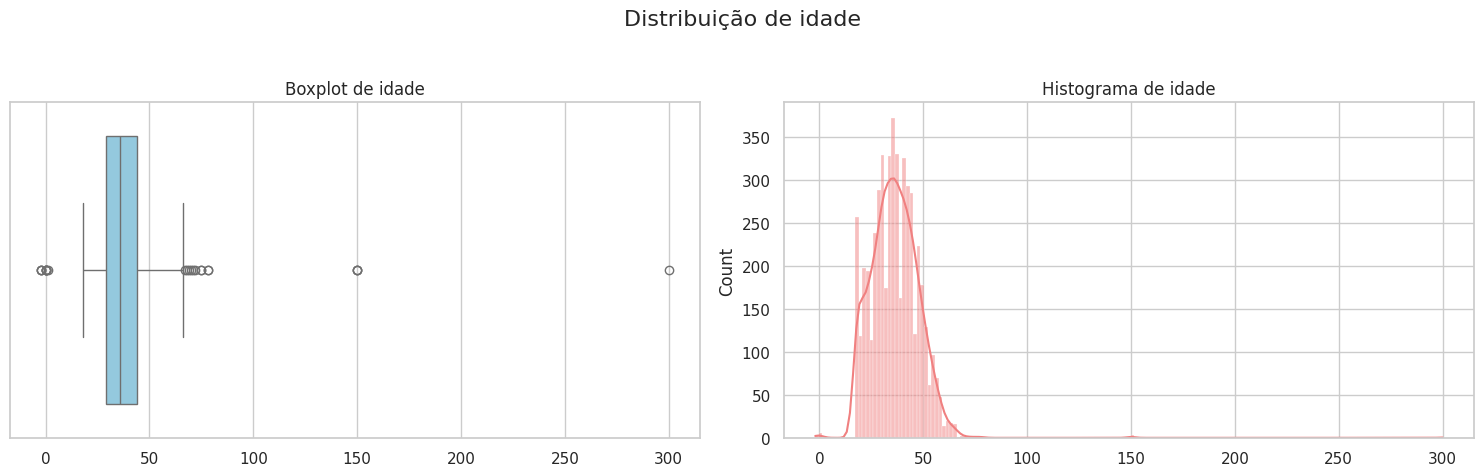

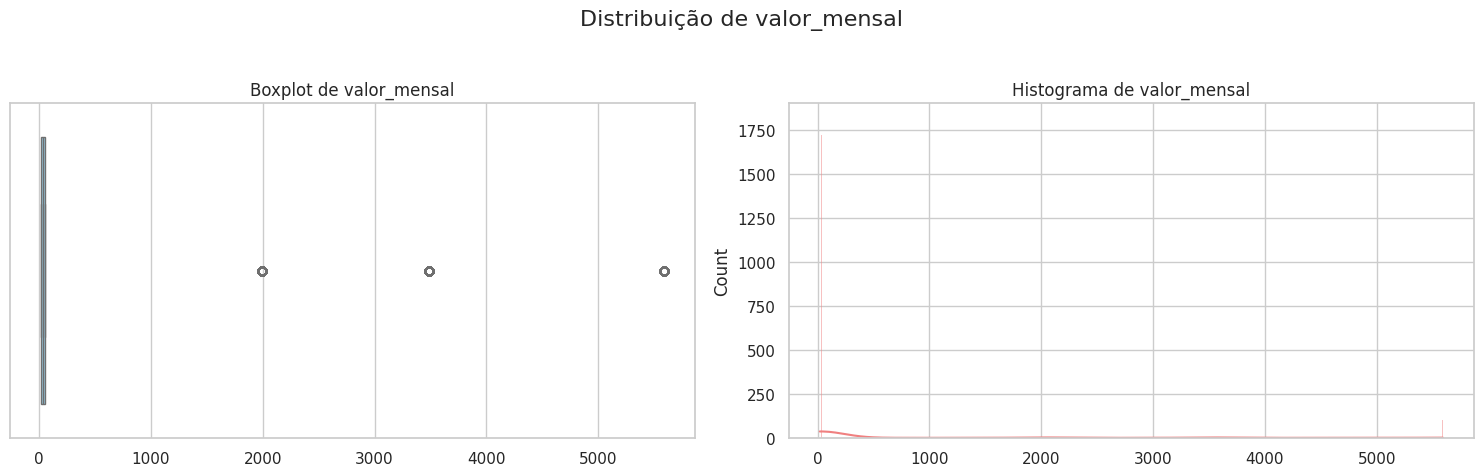

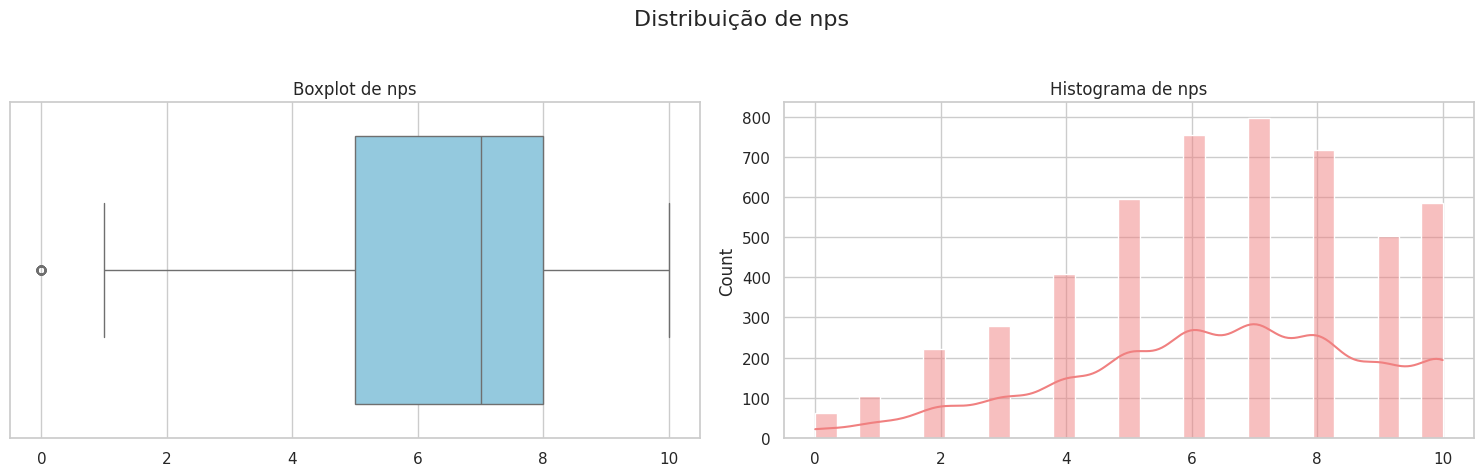

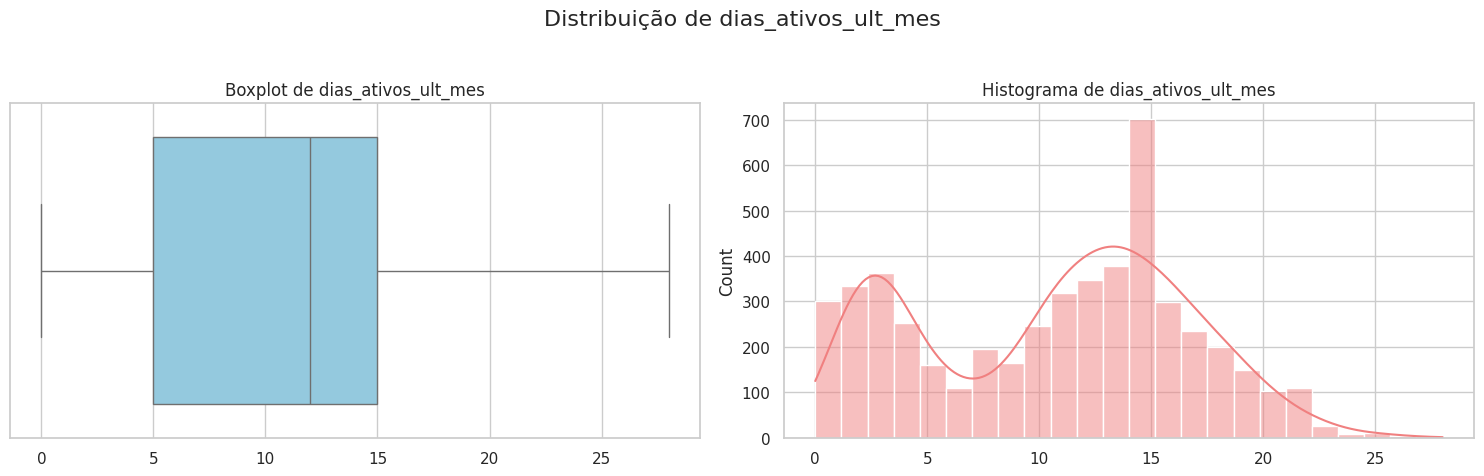

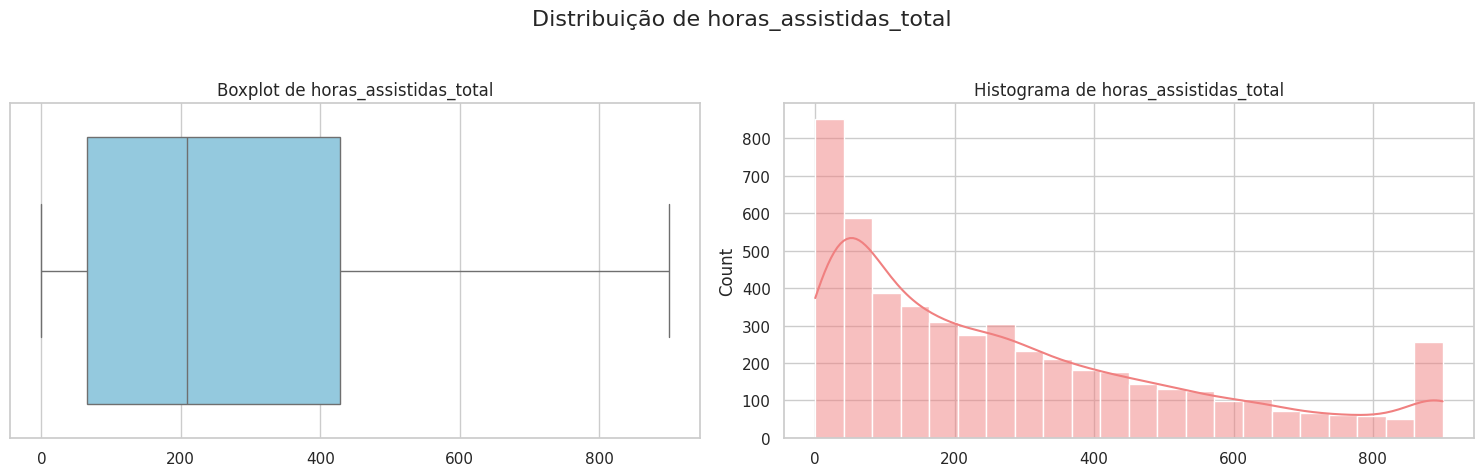

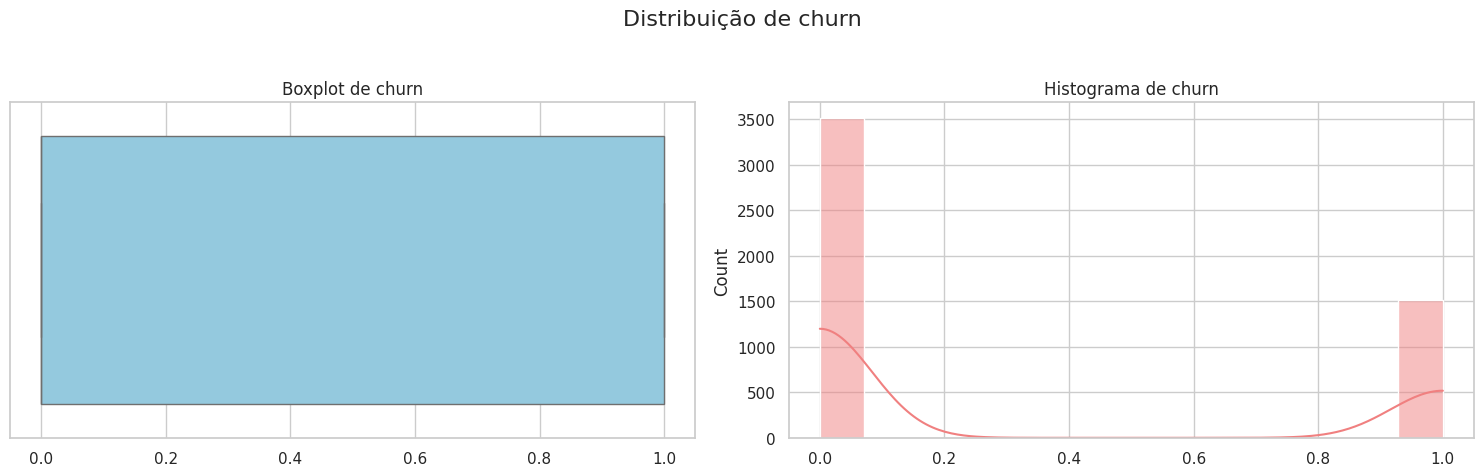

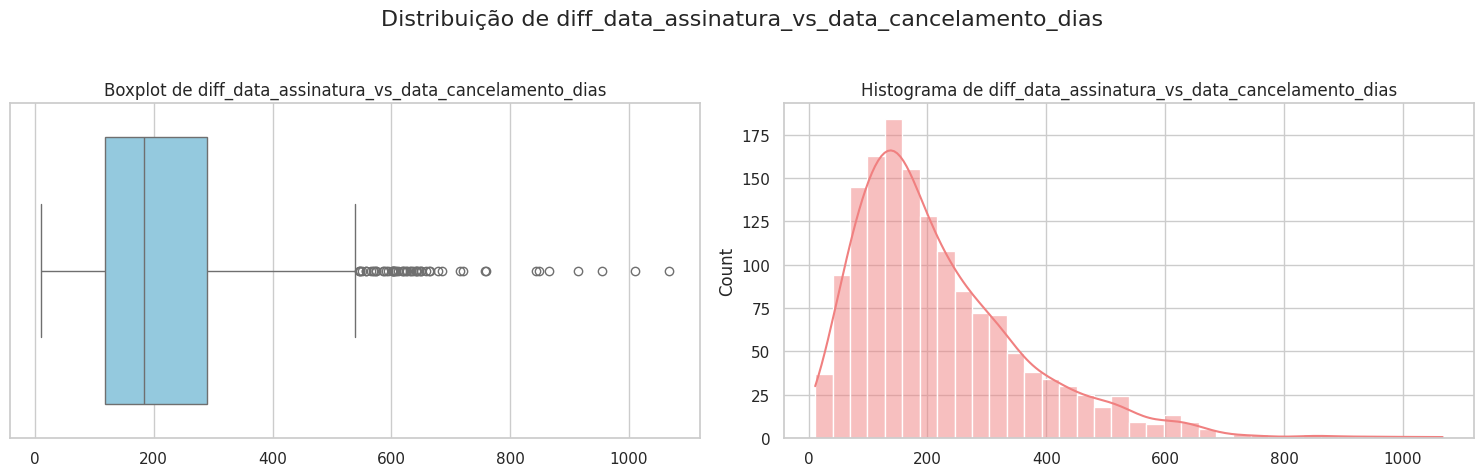

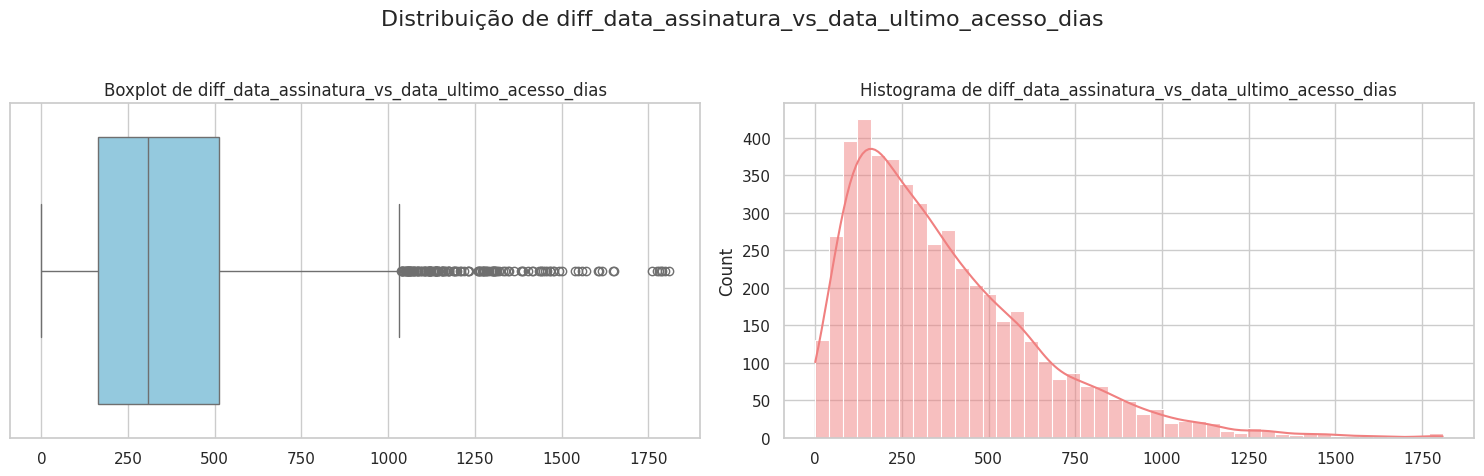

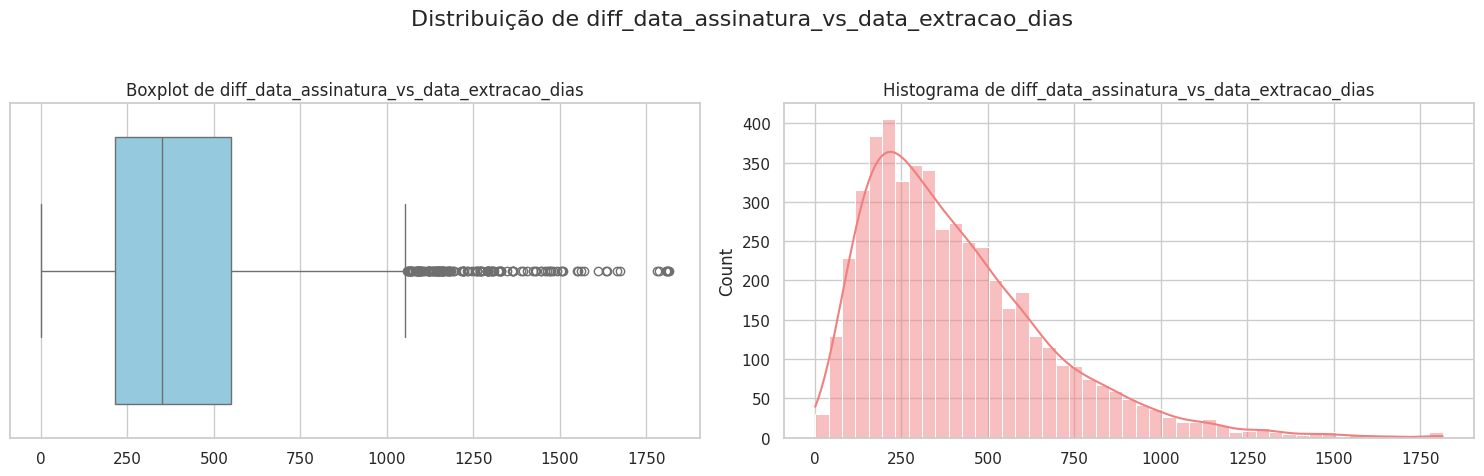

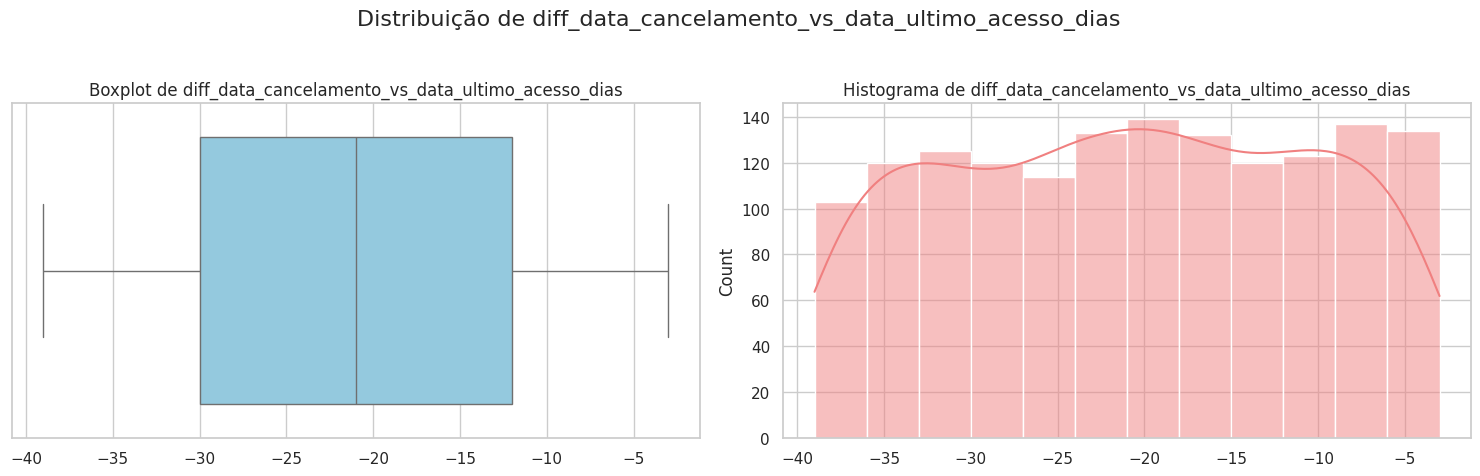

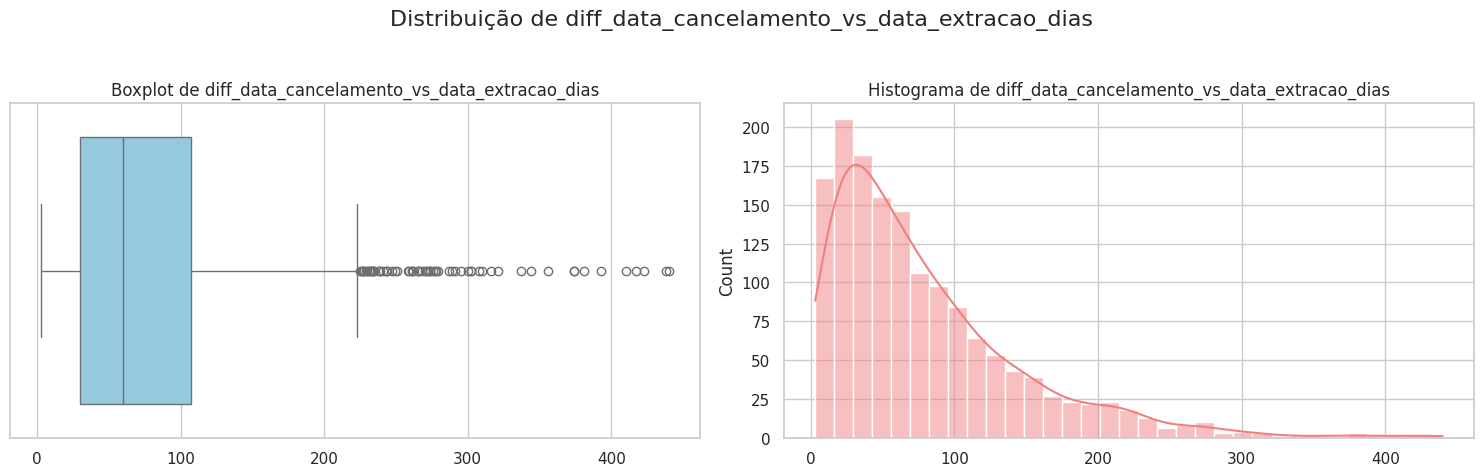

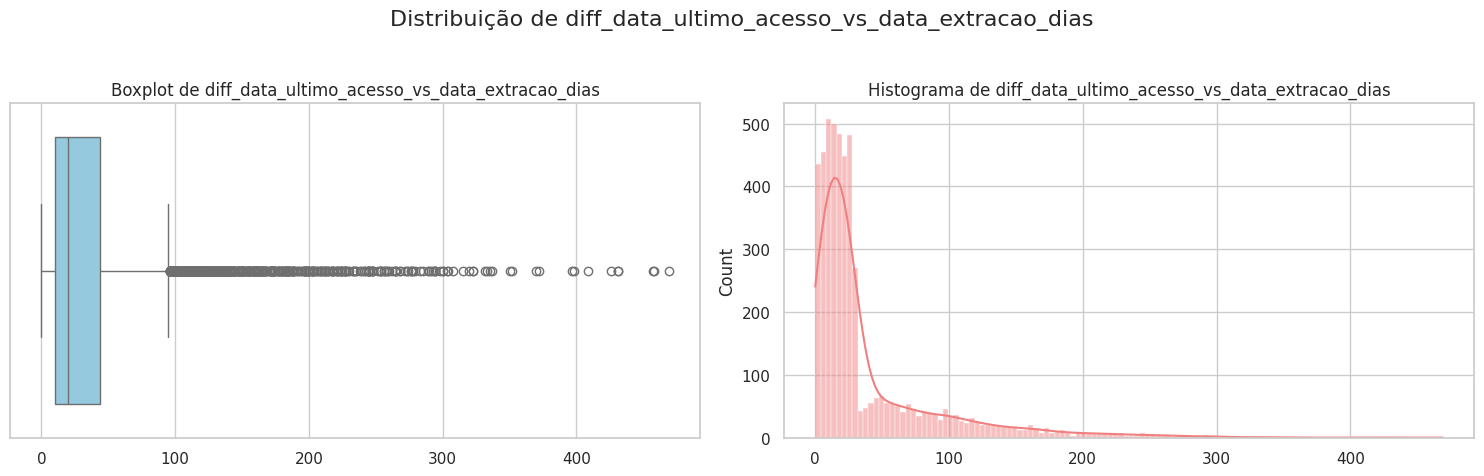

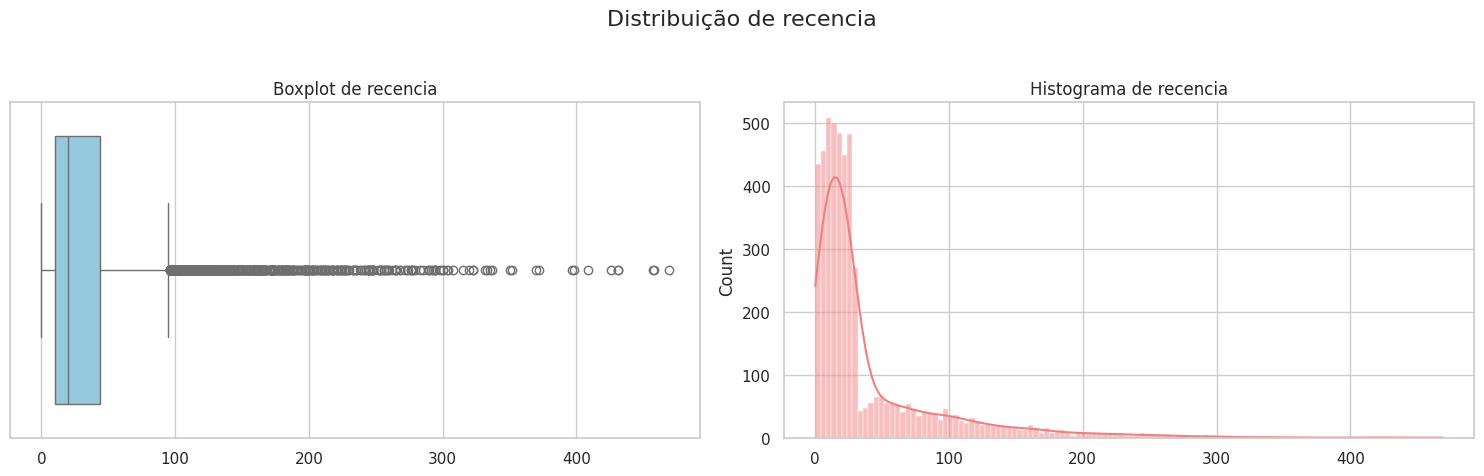

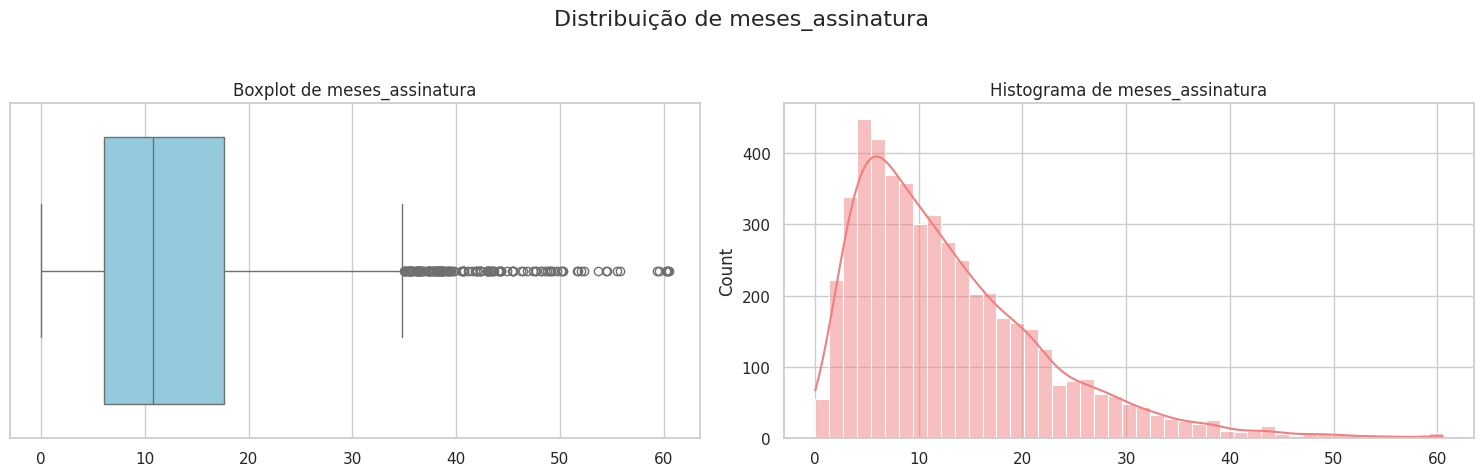

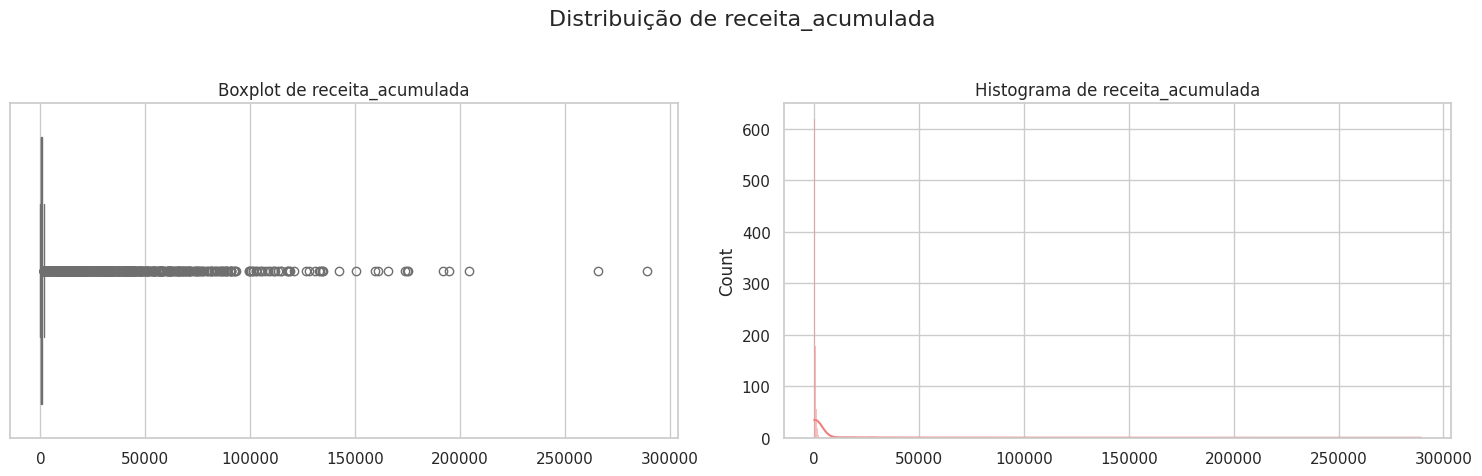

In [70]:
import matplotlib.pyplot as plt
import seaborn as sns

# Identificar colunas numéricas, excluindo 'cliente_id'
# Usaremos df_filtrado para as visualizações
numerical_cols_for_plot = df_filtrado.select_dtypes(include=['int64', 'float64']).columns.tolist()
if 'cliente_id' in numerical_cols_for_plot:
    numerical_cols_for_plot.remove('cliente_id')

print(f"Gerando boxplots e histogramas para as seguintes colunas numéricas: {numerical_cols_for_plot}")

for col in numerical_cols_for_plot:
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    fig.suptitle(f'Distribuição de {col}', fontsize=16)

    # Boxplot
    sns.boxplot(x=df_filtrado[col], ax=axes[0], color='skyblue')
    axes[0].set_title(f'Boxplot de {col}')
    axes[0].set_xlabel('') # Remove x-label to avoid redundancy with suptitle

    # Histograma
    sns.histplot(df_filtrado[col].dropna(), kde=True, ax=axes[1], color='lightcoral')
    axes[1].set_title(f'Histograma de {col}')
    axes[1].set_xlabel('') # Remove x-label to avoid redundancy with suptitle

    plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Ajusta o layout para evitar sobreposição de títulos
    plt.show()

In [71]:
# Filtrar o DataFrame df_filtrado para remover linhas onde a idade é menor que 18 ou maior que 90
initial_rows_filtered = len(df_filtrado)
df_filtrado = df_filtrado[(df_filtrado['idade'] >= 18) & (df_filtrado['idade'] <= 90)].copy()
final_rows_filtered = len(df_filtrado)

print(f"Linhas em df_filtrado antes do filtro de idade: {initial_rows_filtered}")
print(f"Linhas em df_filtrado após o filtro de idade: {final_rows_filtered}")
print(f"Foram removidas {initial_rows_filtered - final_rows_filtered} linhas por idade fora do intervalo [18, 90].")

print("\nPrimeiras 5 linhas do DataFrame df_filtrado após o filtro de idade:")
display(df_filtrado.head())

Linhas em df_filtrado antes do filtro de idade: 5024
Linhas em df_filtrado após o filtro de idade: 5011
Foram removidas 13 linhas por idade fora do intervalo [18, 90].

Primeiras 5 linhas do DataFrame df_filtrado após o filtro de idade:


,cliente_id,idade,plano,ciclo,valor_mensal,regiao,canal_aquisicao,nps,data_assinatura,data_cancelamento,...,churn,diff_data_assinatura_vs_data_cancelamento_dias,diff_data_assinatura_vs_data_ultimo_acesso_dias,diff_data_assinatura_vs_data_extracao_dias,diff_data_cancelamento_vs_data_ultimo_acesso_dias,diff_data_cancelamento_vs_data_extracao_dias,diff_data_ultimo_acesso_vs_data_extracao_dias,recencia,meses_assinatura,receita_acumulada
0,5746,36,básico,Anual,19.9,Sudeste,indicação,6,2023-04-11,NaT,...,0,NaN,293.0,295,NaN,NaN,2.0,2.0,9.833333,195.683333
1,4100,48,padrão,Mensal,34.9,Sudeste,orgânico,8,2022-06-02,NaT,...,0,NaN,607.0,608,NaN,NaN,1.0,1.0,20.266667,707.306667
2,4690,48,premium,Mensal,55.9,Nordeste,orgânico,4,2021-03-20,2022-11-17,...,1,607.0,590.0,1047,-17.0,440.0,457.0,457.0,20.233333,1131.043333
3,3454,46,básico,Anual,1990.0,Sul,google,10,2023-04-02,NaT,...,0,NaN,286.0,304,NaN,NaN,18.0,18.0,10.133333,20165.333333
4,1437,46,básico,Mensal,19.9,Norte,indicação,8,2023-04-21,NaT,...,0,NaN,270.0,285,NaN,NaN,15.0,15.0,9.500000,189.050000


In [72]:
# Filtrar df_filtrado para mostrar linhas onde 'valor_mensal' é maior que 1000
print("Linhas onde 'valor_mensal' é maior que 1000:")
display(df_filtrado[df_filtrado['valor_mensal'] > 1000])

Linhas onde 'valor_mensal' é maior que 1000:


,cliente_id,idade,plano,ciclo,valor_mensal,regiao,canal_aquisicao,nps,data_assinatura,data_cancelamento,...,churn,diff_data_assinatura_vs_data_cancelamento_dias,diff_data_assinatura_vs_data_ultimo_acesso_dias,diff_data_assinatura_vs_data_extracao_dias,diff_data_cancelamento_vs_data_ultimo_acesso_dias,diff_data_cancelamento_vs_data_extracao_dias,diff_data_ultimo_acesso_vs_data_extracao_dias,recencia,meses_assinatura,receita_acumulada
3,3454,46,básico,Anual,1990.0,Sul,google,10,2023-04-02,NaT,...,0,NaN,286.0,304,NaN,NaN,18.0,18.0,10.133333,20165.333333
14,5581,18,padrão,Mensal,3490.0,Sudeste,orgânico,7,2023-07-22,NaT,...,0,NaN,189.0,193,NaN,NaN,4.0,4.0,6.433333,22452.333333
29,5979,31,padrão,Mensal,3490.0,Sudeste,instagram,10,2023-08-22,NaT,...,0,NaN,134.0,162,NaN,NaN,28.0,28.0,5.400000,18846.000000
34,1433,56,padrão,Anual,3490.0,NaN,orgânico,9,2023-04-14,NaT,...,0,NaN,283.0,292,NaN,NaN,9.0,9.0,9.733333,33969.333333
42,4776,61,básico,Anual,1990.0,Sudeste,orgânico,4,2023-10-01,2023-12-15,...,1,75.0,55.0,122,-20.0,47.0,67.0,67.0,2.500000,4975.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4979,4984,30,padrão,Anual,3490.0,Sudeste,indicação,7,2020-12-01,NaT,...,0,NaN,1138.0,1156,NaN,NaN,18.0,18.0,38.533333,134481.333333
4991,2396,23,padrão,Anual,3490.0,Nordeste,orgânico,8,2021-04-14,NaT,...,0,NaN,1017.0,1022,NaN,NaN,5.0,5.0,34.066667,118892.666667
5000,5926,37,padrão,Anual,3490.0,Centro-Oeste,orgânico,10,2022-12-01,NaT,...,0,NaN,402.0,426,NaN,NaN,24.0,24.0,14.200000,49558.000000
5006,4388,18,básico,Anual,1990.0,Nordeste,instagram,9,2023-05-03,NaT,...,0,NaN,251.0,273,NaN,NaN,22.0,22.0,9.100000,18109.000000


In [73]:

# Contar os valores distintos da coluna 'valor_mensal' em df_filtrado
distinct_valor_mensal_count = df_filtrado['valor_mensal'].nunique()

print(f"Número de valores distintos na coluna 'valor_mensal': {distinct_valor_mensal_count}")

Número de valores distintos na coluna 'valor_mensal': 6


In [74]:
# Contar os valores únicos e suas frequências na coluna 'valor_mensal'
print("Valores únicos e suas contagens na coluna 'valor_mensal':")
display(df_filtrado['valor_mensal'].value_counts())

Valores únicos e suas contagens na coluna 'valor_mensal':


,count
valor_mensal,
19.9,1806
34.9,1712
55.9,891
1990.0,252
3490.0,246
5590.0,104


In [75]:
# Dividir por 100 os valores da coluna 'valor_mensal' que são maiores que 1900
print("Valores de 'valor_mensal' antes da divisão:")
display(df_filtrado[df_filtrado['valor_mensal'] > 1900][['valor_mensal']].head())

df_filtrado.loc[df_filtrado['valor_mensal'] > 1900, 'valor_mensal'] = df_filtrado['valor_mensal'] / 100

print("\nPrimeiras 5 linhas do DataFrame df_filtrado após a divisão (onde aplicável):")
display(df_filtrado.head())

print("\nValores de 'valor_mensal' após a divisão (exibindo os modificados):")
display(df_filtrado[df_filtrado['valor_mensal'] > 19][['valor_mensal']].head()) # Assuming 19 is a threshold to show modified high values

Valores de 'valor_mensal' antes da divisão:


,valor_mensal
3,1990.0
14,3490.0
29,3490.0
34,3490.0
42,1990.0



Primeiras 5 linhas do DataFrame df_filtrado após a divisão (onde aplicável):


,cliente_id,idade,plano,ciclo,valor_mensal,regiao,canal_aquisicao,nps,data_assinatura,data_cancelamento,...,churn,diff_data_assinatura_vs_data_cancelamento_dias,diff_data_assinatura_vs_data_ultimo_acesso_dias,diff_data_assinatura_vs_data_extracao_dias,diff_data_cancelamento_vs_data_ultimo_acesso_dias,diff_data_cancelamento_vs_data_extracao_dias,diff_data_ultimo_acesso_vs_data_extracao_dias,recencia,meses_assinatura,receita_acumulada
0,5746,36,básico,Anual,19.9,Sudeste,indicação,6,2023-04-11,NaT,...,0,NaN,293.0,295,NaN,NaN,2.0,2.0,9.833333,195.683333
1,4100,48,padrão,Mensal,34.9,Sudeste,orgânico,8,2022-06-02,NaT,...,0,NaN,607.0,608,NaN,NaN,1.0,1.0,20.266667,707.306667
2,4690,48,premium,Mensal,55.9,Nordeste,orgânico,4,2021-03-20,2022-11-17,...,1,607.0,590.0,1047,-17.0,440.0,457.0,457.0,20.233333,1131.043333
3,3454,46,básico,Anual,19.9,Sul,google,10,2023-04-02,NaT,...,0,NaN,286.0,304,NaN,NaN,18.0,18.0,10.133333,20165.333333
4,1437,46,básico,Mensal,19.9,Norte,indicação,8,2023-04-21,NaT,...,0,NaN,270.0,285,NaN,NaN,15.0,15.0,9.500000,189.050000



Valores de 'valor_mensal' após a divisão (exibindo os modificados):


,valor_mensal
0,19.9
1,34.9
2,55.9
3,19.9
4,19.9


In [76]:
# Contar os valores únicos e suas frequências na coluna 'valor_mensal'
print("Valores únicos e suas contagens na coluna 'valor_mensal':")
display(df_filtrado['valor_mensal'].value_counts())


Valores únicos e suas contagens na coluna 'valor_mensal':


,count
valor_mensal,
19.9,2058
34.9,1958
55.9,995


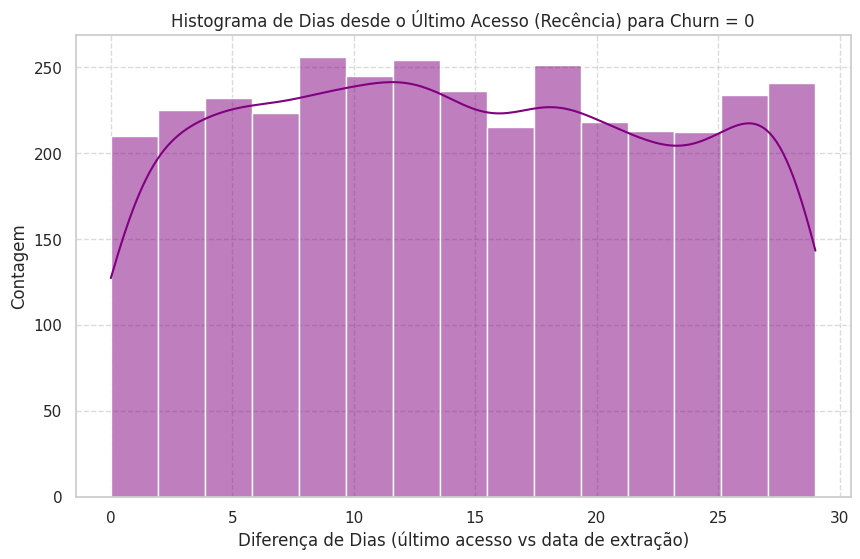

In [78]:
import matplotlib.pyplot as plt
import seaborn as sns

# Filtrar o DataFrame para churn == 0 (clientes ativos)
df_churn_0 = df_filtrado[df_filtrado['churn'] == 0]

# Criar o histograma usando o nome exato da coluna no DataFrame
plt.figure(figsize=(10, 6))
sns.histplot(df_churn_0['diff_data_ultimo_acesso_vs_data_extracao_dias'].dropna(), kde=True, color='purple')
plt.title('Histograma de Dias desde o Último Acesso (Recência) para Churn = 0')
plt.xlabel('Diferença de Dias (último acesso vs data de extração)')
plt.ylabel('Contagem')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

##Criando novas variáveis

In [79]:
import numpy as np

# 1. recencia = diff_data_ultimo_acesso_vs_data_extracao_dias (representando a diferença de dias correspondente)
df['recencia'] = df['diff_data_ultimo_acesso_vs_data_extracao_dias']

# 2. meses_assinatura = diff_data_assinatura_vs_data_cancelamento_dias/30
# se data_cancelamento for nula (cliente ativo), use (data_extracao - data_assinatura)/30 no lugar.
# Nota: O prompt diz (data_assinatura - data_extracao)/30, mas no fluxo cronológico correto é (data_extracao - data_assinatura) correspondente a 'diff_data_assinatura_vs_data_extracao_dias'
df['meses_assinatura'] = np.where(
    df['data_cancelamento'].isnull(),
    df['diff_data_assinatura_vs_data_extracao_dias'] / 30,
    df['diff_data_assinatura_vs_data_cancelamento_dias'] / 30
)

# 3. receita_acumulada = valor_mensal * meses_assinatura
df['receita_acumulada'] = df['valor_mensal'] * df['meses_assinatura']

# Exibir exemplo das novas colunas criadas
display(df[['recencia', 'meses_assinatura', 'receita_acumulada', 'data_cancelamento', 'data_assinatura', 'data_extracao', 'valor_mensal']].head())

,recencia,meses_assinatura,receita_acumulada,data_cancelamento,data_assinatura,data_extracao,valor_mensal
0,2.0,9.833333,195.683333,NaT,2023-04-11,2024-01-31,19.9
1,1.0,20.266667,707.306667,NaT,2022-06-02,2024-01-31,34.9
2,457.0,20.233333,1131.043333,2022-11-17,2021-03-20,2024-01-31,55.9
3,18.0,10.133333,20165.333333,NaT,2023-04-02,2024-01-31,1990.0
4,15.0,9.500000,189.050000,NaT,2023-04-21,2024-01-31,19.9


In [80]:
# Verificar informações e estatísticas descritivas das novas colunas
print("Informações das novas colunas:")
display(df_filtrado[['recencia', 'meses_assinatura', 'receita_acumulada']].info())

print("Estatísticas descritivas das novas colunas:")
display(df_filtrado[['recencia', 'meses_assinatura', 'receita_acumulada']].describe())

Informações das novas colunas:
<class 'pandas.core.frame.DataFrame'>
Index: 5011 entries, 0 to 5024
Data columns (total 3 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   recencia           4961 non-null   float64
 1   meses_assinatura   5011 non-null   float64
 2   receita_acumulada  5011 non-null   float64
dtypes: float64(3)
memory usage: 285.6 KB


None

Estatísticas descritivas das novas colunas:


,recencia,meses_assinatura,receita_acumulada
count,4961.000000,5011.000000,5011.000000
mean,40.452731,12.950376,5401.552585
std,55.112223,9.186362,18441.980330
min,0.000000,0.033333,0.663333
25%,10.000000,6.033333,187.296667
50%,20.000000,10.766667,374.593333
75%,44.000000,17.600000,759.586667
max,469.000000,60.500000,289375.666667


## Conclusões da univiariada - variáveis categóricas


**1. Base suja**
- **`plano`**: "Basico" / "BASICO" / "básico" são o mesmo plano, mas contam separado. O mesmo com Padrão e Premium. Sem unificar, você teria **8 planos** quando existem **3**.
- **`canal_aquisicao`**: pior ainda - 9 grafias para canais: "Organico" / "orgânico", "Indicacao"/"indicação", "IG" / "Instagram" / "instagram", "Google" / "google".

**2. O `?` na região é ausente disfarçado**
São 170 registros com "?", que o `isnull()` não pega porque é texto. Trat-alo como categoria válida criaria uma "região interrogação" nos gráficos, o certo é convertê-lo em nulo.

**3. Insights de negócio**
- Concentração no Sudeste
- Produto predominantemente Mensal
- Distribuição dos canais equilibrada

# **ANÁLISE BIVARIADA**

##Filtrar a base para evitar vieses

In [60]:
# Filtrar o DataFrame df_filtrado mantendo apenas clientes com diff_data_assinatura_vs_data_extracao_dias >= 220
df_analise = df_filtrado[df_filtrado['diff_data_assinatura_vs_data_extracao_dias'] >= 220].copy()

# Exibir informações sobre o novo DataFrame
print(f"Quantidade de registros no df_analise: {df_analise.shape[0]}")
display(df_analise.head())

Quantidade de registros no df_analise: 3678


,cliente_id,idade,plano,ciclo,valor_mensal,regiao,canal_aquisicao,nps,data_assinatura,data_cancelamento,...,dias_ativos_ult_mes,horas_assistidas_total,motivo_cancelamento,churn,diff_data_assinatura_vs_data_cancelamento_dias,diff_data_assinatura_vs_data_ultimo_acesso_dias,diff_data_assinatura_vs_data_extracao_dias,diff_data_cancelamento_vs_data_ultimo_acesso_dias,diff_data_cancelamento_vs_data_extracao_dias,diff_data_ultimo_acesso_vs_data_extracao_dias
0,5746,36,básico,Anual,19.9,Sudeste,indicação,6,2023-04-11,NaT,...,15,276.0,NaN,0,NaN,293.0,295,NaN,NaN,2.0
1,4100,48,padrão,Mensal,34.9,Sudeste,orgânico,8,2022-06-02,NaT,...,14,394.9,NaN,0,NaN,607.0,608,NaN,NaN,1.0
2,4690,48,premium,Mensal,55.9,Nordeste,orgânico,4,2021-03-20,2022-11-17,...,5,257.0,PREÇO,1,607.0,590.0,1047,-17.0,440.0,457.0
3,3454,46,básico,Anual,1990.0,Sul,google,10,2023-04-02,NaT,...,19,385.0,NaN,0,NaN,286.0,304,NaN,NaN,18.0
4,1437,46,básico,Mensal,19.9,Norte,indicação,8,2023-04-21,NaT,...,11,205.3,NaN,0,NaN,270.0,285,NaN,NaN,15.0


In [81]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ajustar os valores acima de 1900 na coluna valor_mensal dividindo por 100 (conforme Etapa 15)
df_filtrado['valor_mensal'] = np.where(df_filtrado['valor_mensal'] > 1900, df_filtrado['valor_mensal'] / 100, df_filtrado['valor_mensal'])

# Recriar o df_analise a partir do df_filtrado corrigido
df_analise = df_filtrado[df_filtrado['diff_data_assinatura_vs_data_extracao_dias'] >= 220].copy()

# 1. Criar as variáveis solicitadas na etapa anterior caso não estejam calculadas no df_analise
# recencia = diff_data_ultimo_acesso_vs_data_extracao (que já existe no df como diff_data_ultimo_acesso_vs_data_extracao_dias)
if 'recencia' not in df_analise.columns:
    df_analise['recencia'] = df_analise['diff_data_ultimo_acesso_vs_data_extracao_dias']

# meses_assinatura = diff_data_assinatura_vs_data_cancelamento/30 se data_cancelamento for nula (cliente ativo), use (data_extracao - data_assinatura)/30
if 'meses_assinatura' not in df_analise.columns:
    df_analise['meses_assinatura'] = np.where(
        df_analise['data_cancelamento'].isnull(),
        (df_analise['data_extracao'] - df_analise['data_assinatura']).dt.days / 30,
        (df_analise['data_cancelamento'] - df_analise['data_assinatura']).dt.days / 30
    )

# receita_acumulada = valor_mensal * meses_assinatura
df_analise['receita_acumulada'] = df_analise['valor_mensal'] * df_analise['meses_assinatura']

# Mapeando os nomes exatos das colunas numéricas disponíveis para análise
var_numericas = [
    'idade', 'valor_mensal', 'nps', 'dias_ativos_ult_mes', 'horas_assistidas_total',
    'diff_data_assinatura_vs_data_ultimo_acesso_dias', 'diff_data_assinatura_vs_data_extracao_dias',
    'recencia', 'meses_assinatura', 'receita_acumulada'
]

var_categoricas = ['plano', 'ciclo', 'regiao', 'canal_aquisicao']

##Análise de Variáveis Categóricas vs. Churn (Crosstabs Normalizadas)


Análise da Variável Numérica: idade vs Churn


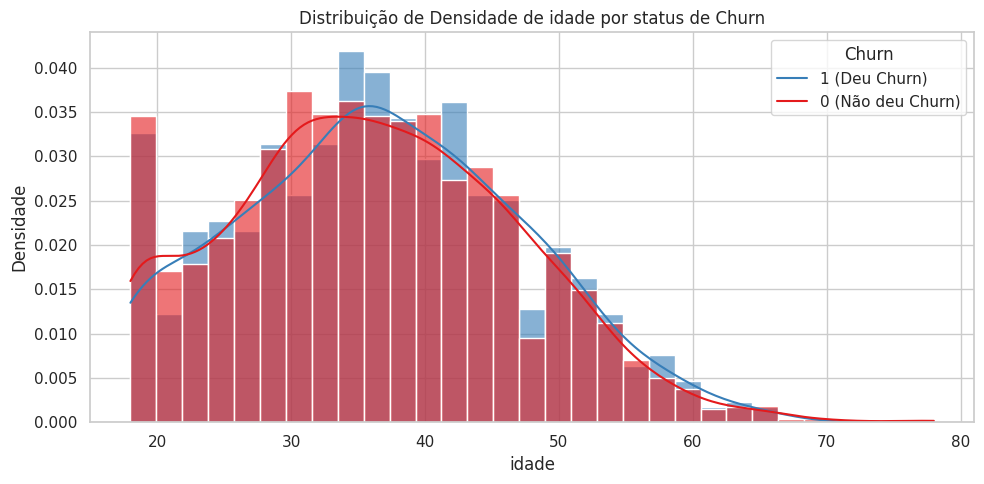

,count,mean,std,min,25%,50%,75%,max
churn,,,,,,,,
0,2780.0,36.125540,10.633567,18.0,29.0,36.0,44.0,78.0
1,888.0,36.632883,10.600266,18.0,29.0,36.0,44.0,66.0



Análise da Variável Numérica: valor_mensal vs Churn


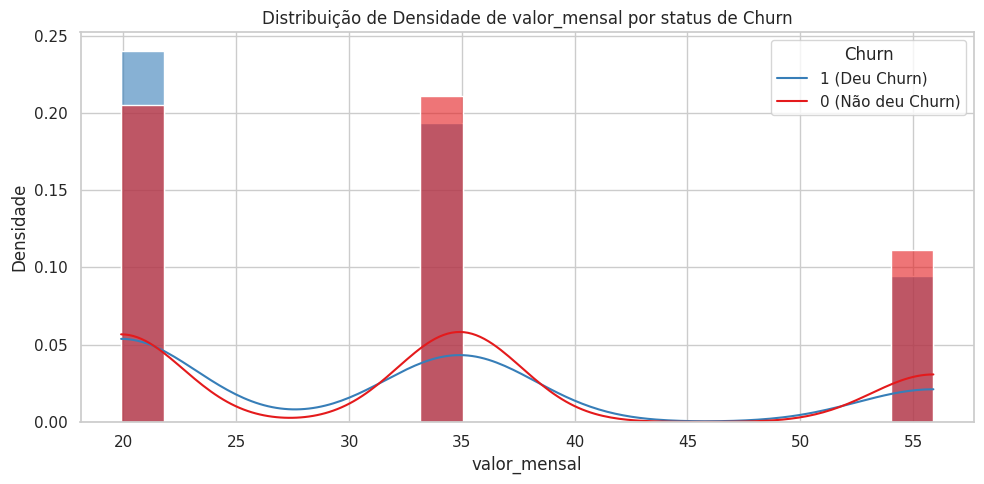

,count,mean,std,min,25%,50%,75%,max
churn,,,,,,,,
0,2780.0,33.496043,13.370968,19.9,19.9,34.9,34.9,55.9
1,888.0,31.835811,13.119920,19.9,19.9,34.9,34.9,55.9



Análise da Variável Numérica: nps vs Churn


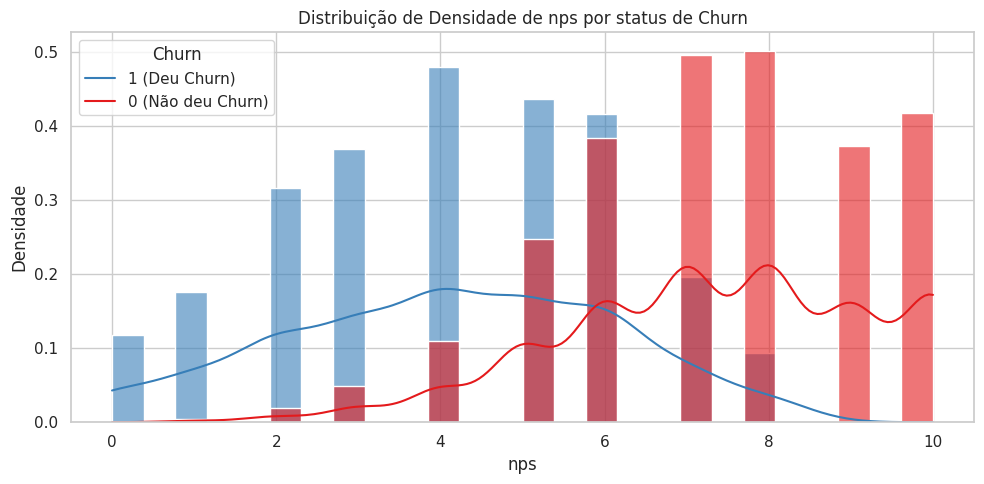

,count,mean,std,min,25%,50%,75%,max
churn,,,,,,,,
0,2780.0,7.376978,1.877014,1.0,6.0,7.0,9.0,10.0
1,888.0,4.090090,2.004165,0.0,3.0,4.0,6.0,8.0



Análise da Variável Numérica: dias_ativos_ult_mes vs Churn


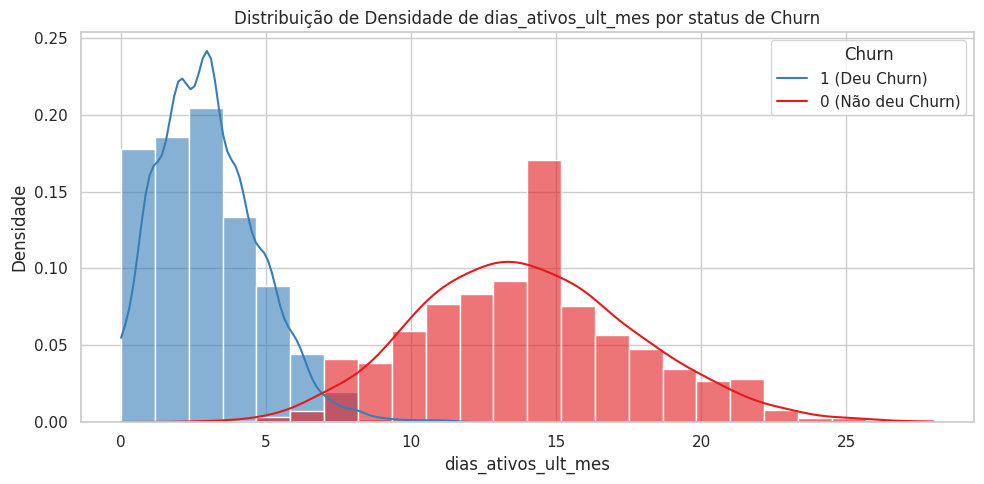

,count,mean,std,min,25%,50%,75%,max
churn,,,,,,,,
0,2780.0,13.995324,3.755046,3.0,11.0,14.0,16.0,28.0
1,888.0,2.967342,1.721950,0.0,2.0,3.0,4.0,11.0



Análise da Variável Numérica: horas_assistidas_total vs Churn


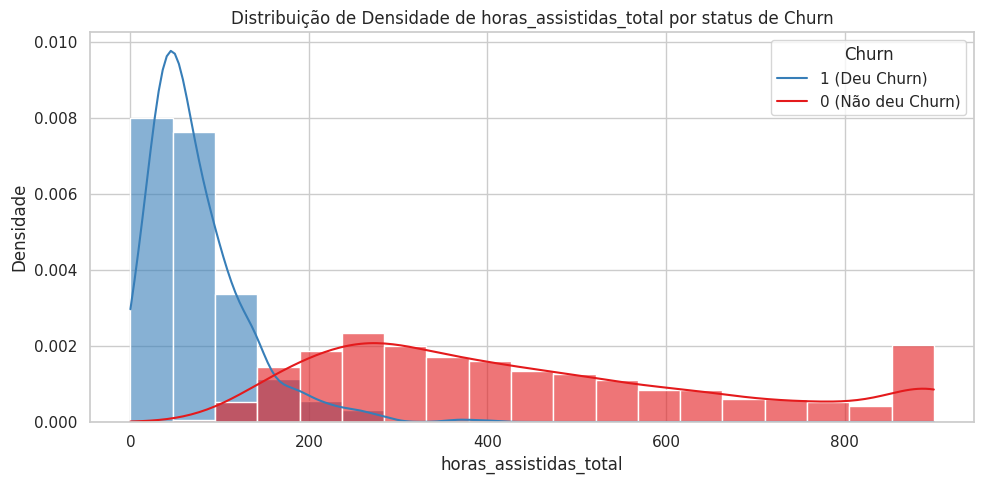

,count,mean,std,min,25%,50%,75%,max
churn,,,,,,,,
0,2780.0,448.891475,226.739374,73.9,265.450,395.60,600.9,900.0
1,888.0,73.143131,55.191559,0.0,35.925,58.95,96.6,400.0



Análise da Variável Numérica: diff_data_assinatura_vs_data_ultimo_acesso_dias vs Churn


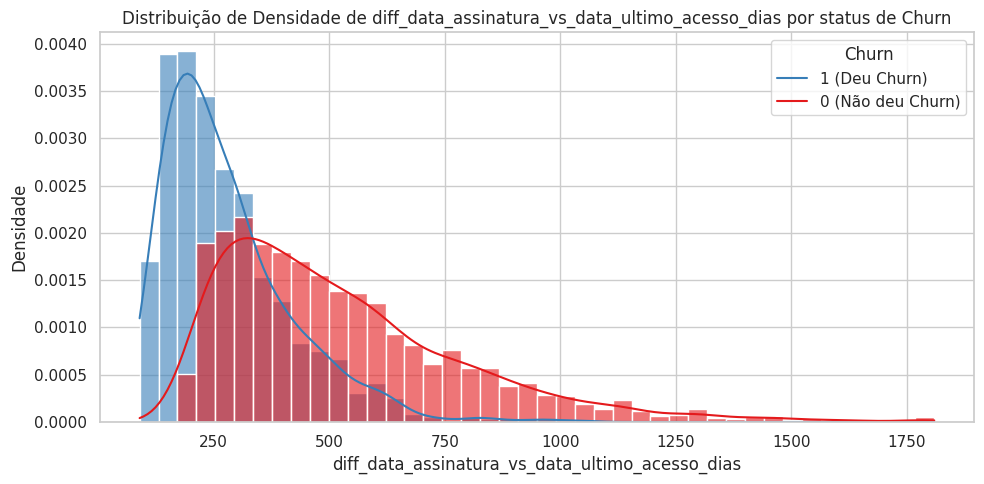

,count,mean,std,min,25%,50%,75%,max
churn,,,,,,,,
0,2755.0,528.301270,266.179458,192.0,327.0,465.0,659.0,1809.0
1,878.0,278.715262,138.580418,90.0,176.0,244.0,342.5,1040.0



Análise da Variável Numérica: diff_data_assinatura_vs_data_extracao_dias vs Churn


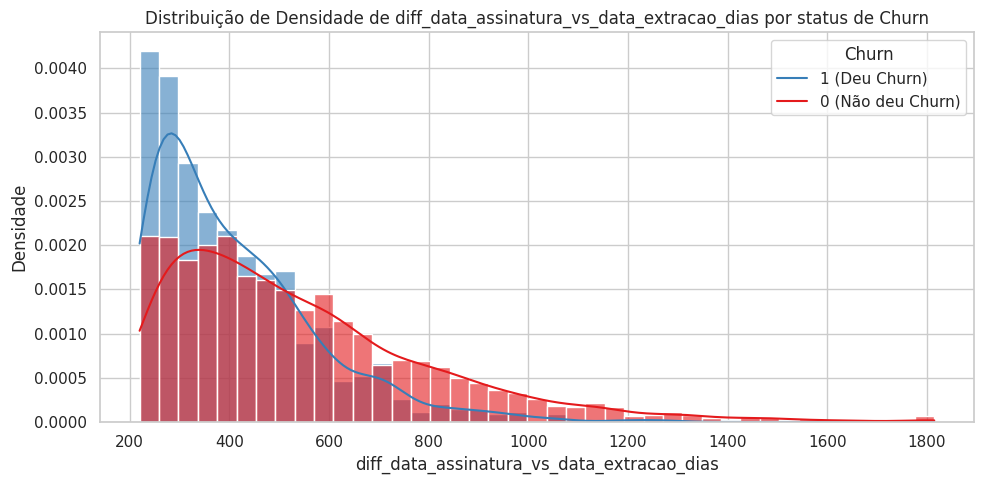

,count,mean,std,min,25%,50%,75%,max
churn,,,,,,,,
0,2780.0,542.666187,265.461831,220.0,341.0,481.0,673.25,1815.0
1,888.0,409.548423,166.733604,220.0,282.0,364.5,495.00,1276.0



Análise da Variável Numérica: recencia vs Churn


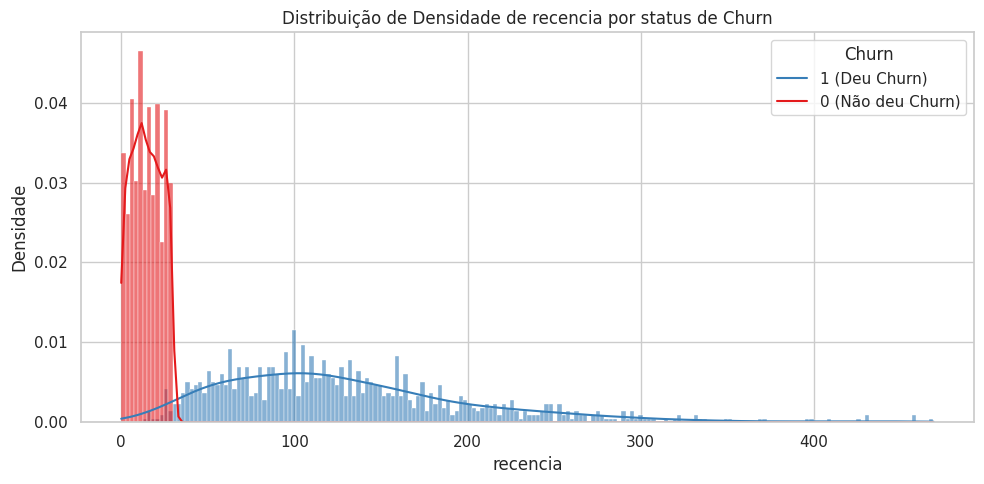

,count,mean,std,min,25%,50%,75%,max
churn,,,,,,,,
0,2755.0,14.603993,8.493044,0.0,8.00,14.0,22.0,29.0
1,878.0,130.011390,74.106997,13.0,75.25,117.0,165.0,469.0



Análise da Variável Numérica: meses_assinatura vs Churn


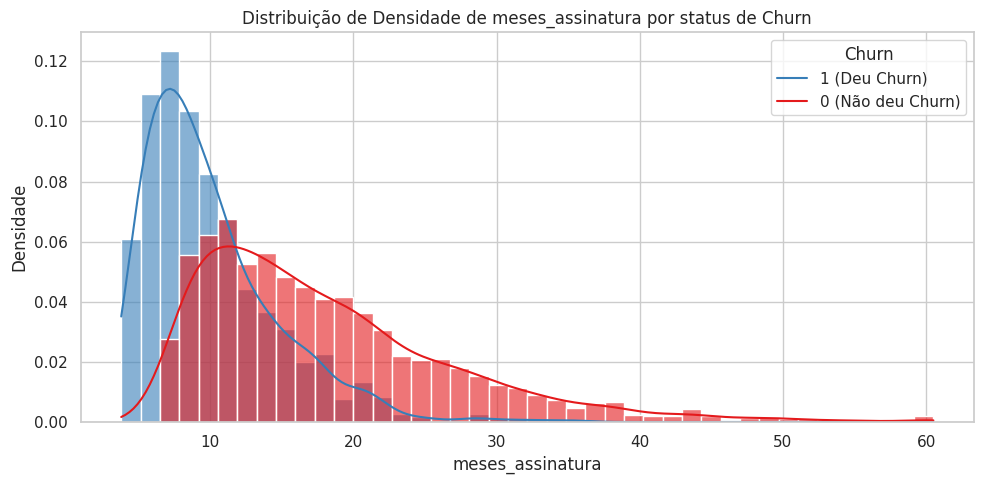

,count,mean,std,min,25%,50%,75%,max
churn,,,,,,,,
0,2780.0,18.088873,8.848728,7.333333,11.366667,16.033333,22.441667,60.500000
1,888.0,10.006156,4.615595,3.800000,6.666667,8.900000,12.108333,35.566667



Análise da Variável Numérica: receita_acumulada vs Churn


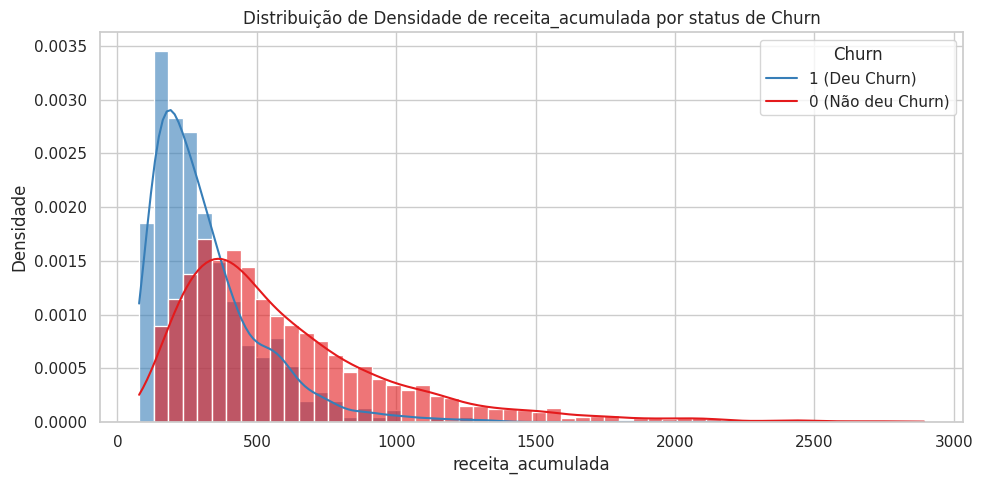

,count,mean,std,min,25%,50%,75%,max
churn,,,,,,,,
0,2780.0,605.311556,396.917467,145.933333,329.013333,491.508333,762.103333,2893.756667
1,888.0,315.519917,195.137065,77.610000,172.173333,262.680000,392.043333,1341.600000


In [82]:
# 2. Análise de Variáveis Numéricas
sns.set_theme(style="whitegrid")

for col in var_numericas:
    if col in df_analise.columns:
        print(f"\n" + "="*50)
        print(f"Análise da Variável Numérica: {col} vs Churn")
        print("="*50)

        # 1. Histograma de densidade sobreposto
        plt.figure(figsize=(10, 5))
        sns.histplot(data=df_analise, x=col, hue='churn', kde=True, stat="density", common_norm=False, palette='Set1', alpha=0.6)
        plt.title(f'Distribuição de Densidade de {col} por status de Churn')
        plt.xlabel(col)
        plt.ylabel('Densidade')
        plt.legend(title='Churn', labels=['1 (Deu Churn)', '0 (Não deu Churn)'])
        plt.tight_layout()
        plt.show()

        # 2. Tabela de estatísticas descritivas
        stats = df_analise.groupby('churn')[col].describe()
        display(stats)

In [63]:
# 3. Análise de Variáveis Categóricas
for col in var_categoricas:
    if col in df_analise.columns:
        print(f"\n" + "="*50)
        print(f"Taxa de Churn por Categoria: {col}")
        print("="*50)

        # Calcular a taxa de churn em porcentagem
        tabela_churn = df_analise.groupby(col).agg(
            Total=('churn', 'count'),
            Churns=('churn', 'sum')
        ).reset_index()

        tabela_churn['Taxa_Churn_%'] = (tabela_churn['Churns'] / tabela_churn['Total'] * 100).round(2)
        display(tabela_churn)


Taxa de Churn por Categoria: plano


,plano,Total,Churns,Taxa_Churn_%
0,básico,1490,405,27.18
1,padrão,1441,326,22.62
2,premium,747,159,21.29



Taxa de Churn por Categoria: ciclo


,ciclo,Total,Churns,Taxa_Churn_%
0,Anual,919,221,24.05
1,Mensal,2759,669,24.25



Taxa de Churn por Categoria: regiao


,regiao,Total,Churns,Taxa_Churn_%
0,Centro-Oeste,355,93,26.20
1,Nordeste,721,173,23.99
2,Norte,297,76,25.59
3,Sudeste,1467,338,23.04
4,Sul,710,175,24.65



Taxa de Churn por Categoria: canal_aquisicao


,canal_aquisicao,Total,Churns,Taxa_Churn_%
0,google,637,172,27.00
1,indicação,798,181,22.68
2,instagram,1130,281,24.87
3,orgânico,1113,256,23.00


Cuidados importantes com conclusões precipitadas

**dias_ativos_ult_mes** — Quem já deu churn não teve acesso nos últimos meses, então aparece zerado por definição — não porque usava pouco, mas porque já tinha saído.

**data_ultimo_acesso (e a recência derivada dela)** — Mesma contaminação. Para quem cancelou, o último acesso trava perto da data de saída, então a recência reflete o churn que já aconteceu, não um comportamento que o antecede. Serve para descrever engajamento entre ativos, mas como preditor de churn é enganosa

**horas_assistidas_total** — Viés parcial em 2 frentes. Primeiro, quem deu churn parou de assistir antes de sair, então acumula menos horas naturalmente, não é uma CAUSA do churn prévio. Segundo, é confundida pelo tempo de casa: veterano naturalmente acumula mais horas — legal ser normalizada por meses_assinatura para comparar de forma justa

**meses_assinatura** — entre os clientes maduros, quem permanece ativo tem mais tempo de casa acumulado do que quem cancelou, o que é esperado — cliente que não dá churn continua na base acumulando meses, enquanto o do churner congela no cancelamento. A leitura honesta é descritiva: os sobreviventes são, por natureza, mais antigos, e há um sinal real de que quem cancela tende a durar menos. Vale só a ressalva de não transformar isso diretamente numa regra preditiva ("abaixo de X meses = risco"), porque o tempo do churner está fechado e o do ativo ainda corre — a forma rigorosa de medir essa queda de permanência ao longo do tempo é a análise de cohort, que desdobra essa diferença agregada na curva de retenção mês a mês.

**tempo até o churn (data_cancelamento − data_assinatura) **— Só existe para quem deu churn (cancelamento é vazio nos ativos). Não entra em comparação churn vs não-churn; serve para entender quando o churn acontece — foi daí que saíram os 220 dias.

**tempo desde o último acesso até o cancelamento (data_cancelamento − data_ultimo_acesso**) — Também exclusiva de quem cancelou. Descreve o comportamento de saída, não entra em comparação churn vs não-churn

**Qualquer diferença que envolva `data_ultimo_acesso` ou `data_cancelamento` carrega o churn dentro dela**, porque essas duas datas são marcadas pelo próprio desfecho.

As diferenças "limpas" para entender padrão churn x não churn são as que dependem só de `data_assinatura` e `data_extracao` (a maturidade) — e mesmo essa exige o corte para não enganar.

##Conclusões análise bivariada

Aqui estão os insights só da bivariada, com os números do notebook (recorte maduro, ≥220 dias):

**Premissa**: análise feita sobre clientes com pelo menos 220 dias de assinatura — o recorte que garante que a pessoa teve tempo real de dar churn.

1. **NPS é o sinal mais forte** E é um sinal honesto: o NPS é declarado ao longo da relação, não é consequência mecânica do churn. É a primeira candidata a virar alerta precoce de cancelamento.

2. **Idade e valor do plano praticamente não separam.** Idade idêntica nos dois grupos (36 vs 36) e valor mensal consequencia do plano básico x premium. É um achado útil: descarta hipóteses óbvias e evita que o time gaste energia segmentando por essas variáveis.

3. **Ciclo e região**. Anual e mensal têm composição praticamente igual entre churners e não-churners, e a região, vemos maior diferença de churn no Norte e Centro-oeste. O caso do ciclo é contraintuitivo — o compromisso do plano anual não está segurando ninguém de forma perceptível. (Vale lembrar que 75% da base é mensal, o que reduz o contraste possível.)

4. **Canal de aquisição tem efeito leve, mas com valor de negócio.** Quem vem de indicação retém um pouco mais do que quem vem do google e outros canais. Conecta com decisão de marketing: a origem do cliente carrega alguma informação sobre a fidelidade dele — canais diferentes trazem clientes com propensões diferentes.

5. **As variáveis de engajamento PARECEM separar espetacularmente — armadilha.** Dias ativos (14 vs 3), horas assistidas (449 vs 73) e recência (15 vs 130 dias) mostram as maiores diferenças de toda a análise. Mas são **contaminadas por vazamento de target**: a pessoa parou de usar porque saiu, não o contrário *churn causa a variável, não o contrário). A separação é quase circular — elas descrevem o churn que já aconteceu, não o antecipam. Usá-las como "causa" seria o erro mais caro da análise.

# **FRAMEWORKS DE ANÁLISE**

## Framework 1 — Análise de Cohort (retenção)

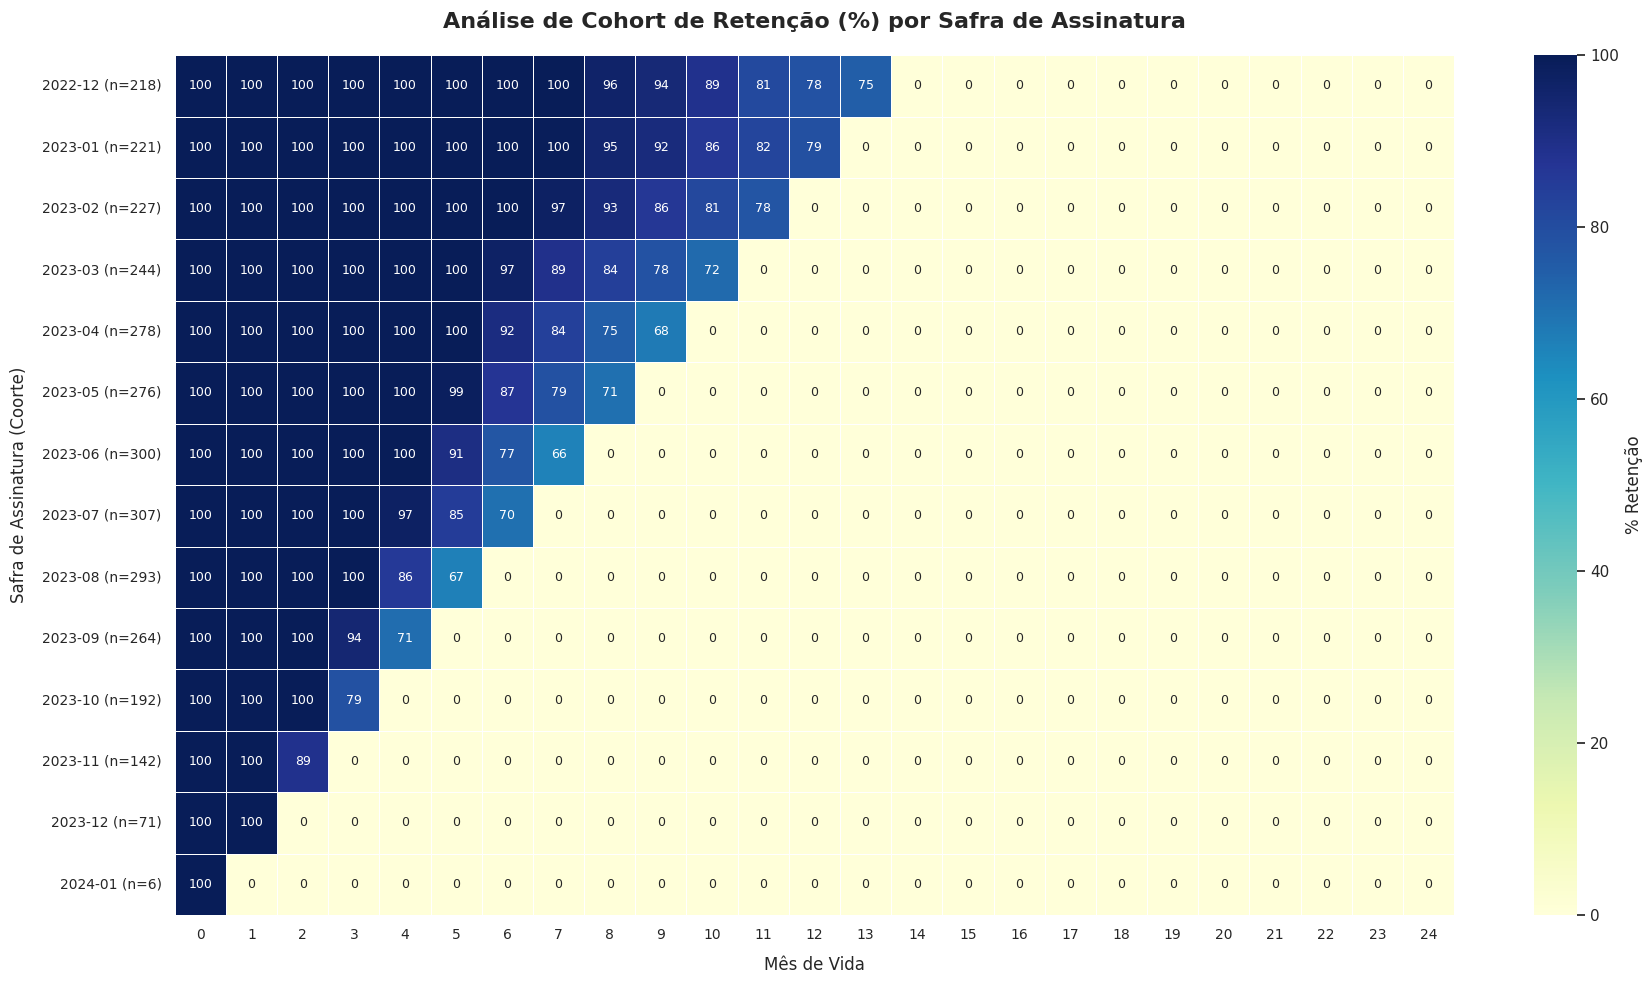

In [64]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Preparação dos dados
df_cohort = df_filtrado.copy()

# Definir coorte como o mês/ano de assinatura (formato YYYY-MM)
df_cohort['cohort'] = df_cohort['data_assinatura'].dt.to_period('M')

# Definir o fim da permanência
df_cohort['fim_permanencia'] = df_cohort['data_cancelamento'].fillna(df_cohort['data_extracao'])

# Função para calcular diferença exata em meses
def diff_meses(d1, d2):
    return (d1.dt.year - d2.dt.year) * 12 + (d1.dt.month - d2.dt.month)

# Diferença em meses entre a assinatura e o fim da permanência
df_cohort['meses_permanecidos'] = diff_meses(df_cohort['fim_permanencia'], df_cohort['data_assinatura'])

# 2. Expansão dos dados para montagem da matriz
# Cada cliente deve aparecer em todos os meses que esteve ativo (do mês 0 até meses_permanecidos)
linhas_expandidas = []
for idx, row in df_cohort.iterrows():
    for m in range(int(row['meses_permanecidos']) + 1):
        linhas_expandidas.append({
            'cohort': row['cohort'],
            'cliente_id': row['cliente_id'],
            'mes_vida': m
        })

df_vida = pd.DataFrame(linhas_expandidas)

# Contar clientes ativos por coorte e mês de vida
cohort_matrix = df_vida.groupby(['cohort', 'mes_vida'])['cliente_id'].nunique().unstack(fill_value=0)

# Obter o tamanho inicial de cada coorte (mês de vida 0)
cohort_sizes = cohort_matrix[0]

# Converter em porcentagem de retenção
retention_matrix = cohort_matrix.divide(cohort_sizes, axis=0) * 100

# 3. Filtrar conforme especificações do usuário
# Mostrar apenas as safras a partir de 2022-12
retention_matrix_filtered = retention_matrix.loc['2022-12':]
cohort_sizes_filtered = cohort_sizes.loc['2022-12':]

# Mostrar apenas os primeiros 24 meses de vida (colunas 0 a 24)
# Garantimos que as colunas existem antes de fatiar
colunas_desejadas = [c for c in range(25) if c in retention_matrix_filtered.columns]
retention_matrix_filtered = retention_matrix_filtered[colunas_desejadas]

# Formatar os rótulos do eixo Y para incluir o tamanho da coorte (ex: "2022-12 (n=180)")
novos_rotulos_y = [f"{str(cohort)} (n={cohort_sizes_filtered[cohort]})" for cohort in retention_matrix_filtered.index]

# 4. Visualização
plt.figure(figsize=(18, 10))
sns.heatmap(
    retention_matrix_filtered,
    annot=True,
    fmt=".0f",
    cmap='YlGnBu',
    linewidths=.5,
    cbar_kws={'label': '% Retenção'},
    yticklabels=novos_rotulos_y,
    annot_kws={"size": 9}
)

plt.title('Análise de Cohort de Retenção (%) por Safra de Assinatura', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Mês de Vida', fontsize=12, labelpad=10)
plt.ylabel('Safra de Assinatura (Coorte)', fontsize=12, labelpad=10)
plt.xticks(fontsize=10)
plt.yticks(rotation=0, fontsize=10)
plt.tight_layout()
plt.show()



*   Há **indício de que a retenção piorou nas safras recentes** — as curvas de 2023 caem visivelmente mais rápido que as de 2022, que caem mais rápido que as de 2021. Isso é um sinal de negócio importante: a qualidade da aquisição ou a experiência do produto pode estar se deteriorando.



,mes_de_vida,churns,clientes_em_risco,taxa_churn_%
0,0,0,5011,0.00
1,1,1,4991,0.02
2,2,2,4878,0.04
3,3,4,4680,0.09
4,4,5,4418,0.11
5,5,3,4089,0.07
6,6,2,3774,0.05
7,7,4,3469,0.12
8,8,4,3190,0.13
9,9,8,2945,0.27


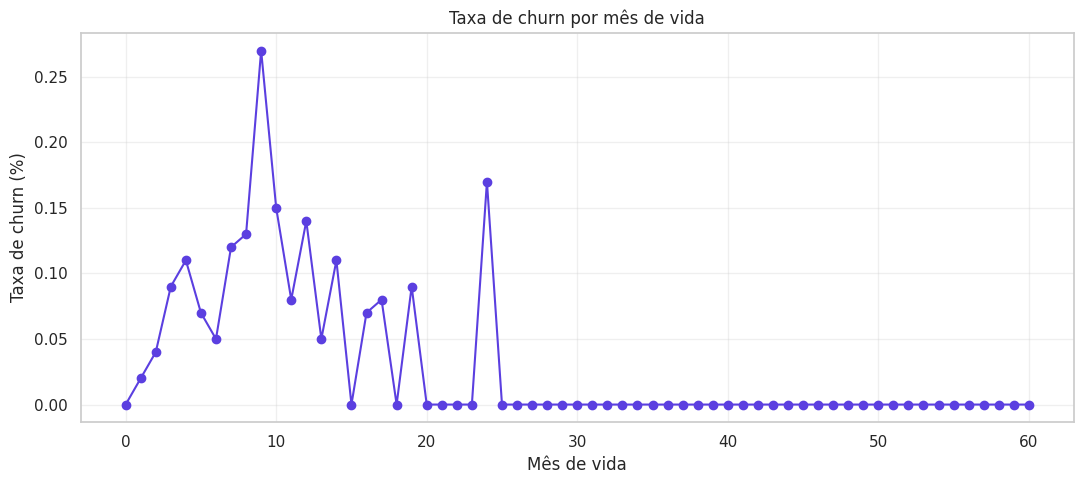

O risco de churn é maior no mês de vida 9 (0.27%).


In [83]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --- Taxa de churn por mês de vida ---
# Denominador: clientes que ALCANÇARAM o mês X (meses_assinatura >= X)
# Numerador: clientes que deram churn EXATAMENTE no mês X

max_mes = int(df_filtrado['meses_assinatura'].max())

linhas = []
for x in range(0, max_mes + 1):
    em_risco = (df_filtrado['meses_assinatura'] >= x).sum()
    churns = ((df_filtrado['churn'] == 1) & (df_filtrado['meses_assinatura'] == x)).sum()
    taxa = (churns / em_risco * 100) if em_risco > 0 else np.nan
    linhas.append({'mes_de_vida': x, 'churns': churns,
                   'clientes_em_risco': em_risco, 'taxa_churn_%': round(taxa, 2)})

tabela_taxa = pd.DataFrame(linhas)
display(tabela_taxa.head(20))

# --- Gráfico ---
plt.figure(figsize=(11, 5))
plt.plot(tabela_taxa['mes_de_vida'], tabela_taxa['taxa_churn_%'],
         marker='o', color='#5B3FE0')
plt.title('Taxa de churn por mês de vida')
plt.xlabel('Mês de vida')
plt.ylabel('Taxa de churn (%)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# --- Conclusão automática ---
pico = tabela_taxa.loc[tabela_taxa['taxa_churn_%'].idxmax()]
print(f"O risco de churn é maior no mês de vida {int(pico['mes_de_vida'])} "
      f"({pico['taxa_churn_%']}%).")

##Framework 2 — RFM adaptado a streaming
Queremos segmentar todos os clientes para ação, inclusive os novos. Como aqui não há compra repetida, adaptamos:
* Recência = `recencia` (dias desde o último acesso — menor é melhor)
* Frequência = `dias_ativos_ult_mes` (uso — maior é melhor)
* Monetário = `valor_mensal` (valor do plano — maior é melhor)

Nota: `dias_ativos` e `recencia` são contaminadas para prever churn, mas aqui o uso é diferente — estamos **descrevendo e segmentando** o estado atual do cliente para ação, não prevendo o desfecho. Nesse contexto, medir engajamento é legítimo.


Removidas 35 linhas com 'recencia' nula.

Quintis para Recência:


,min,max
R,,
5,0.0,6.0
4,7.0,11.0
3,12.0,17.0
2,18.0,23.0
1,24.0,29.0



Quintis para Frequência (dias_ativos_ult_mes):


,min,max
F,,
1,3,11
2,11,13
3,13,15
4,15,17
5,17,28



Quintis para Monetário (valor_mensal):


...


Exemplo de RFM Score:


,cliente_id,R,F,M,RFM_Score
0,5746,5,3,1,531
1,4100,5,3,2,532
3,3454,2,5,1,251
4,1437,3,1,1,311
5,1521,4,1,4,414



Distribuição de Segmentos (Contagem e Porcentagem):


,Contagem,Porcentagem
segmento,,
Regulares,979,28.25
Em risco,813,23.46
Engajados,569,16.42
Adormecidos,556,16.05
Novos/Ativos recentes,548,15.82


/tmp/ipykernel_2948/2476004197.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=segmento_counts.values, y=segmento_counts.index, palette='viridis')


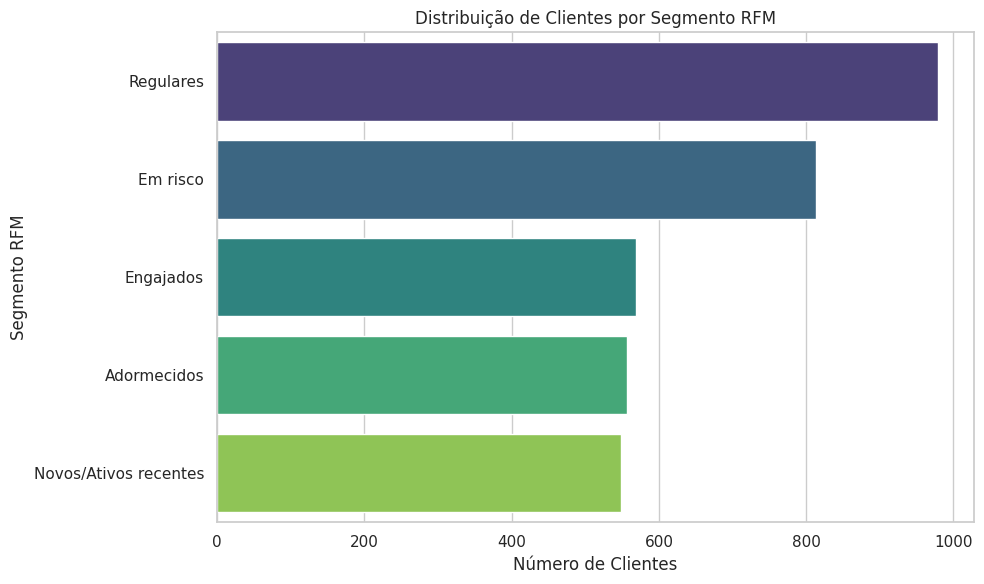

In [84]:
rfm = df_filtrado[df_filtrado['churn'] == 0].copy()

# 1. Tratar nulos na recencia: remover linhas com valores nulos na coluna 'recencia'
initial_rfm_rows = len(rfm)
rfm.dropna(subset=['recencia'], inplace=True)
print(f"Removidas {initial_rfm_rows - len(rfm)} linhas com 'recencia' nula.")

# Atribua notas de 1 a 5 para cada dimensão usando quintis.
# Atenção à direção: na recência, a nota 5 vai para os menores valores (mais recente = melhor),
# então inverta os rótulos dela. Na frequência e no monetário, a nota 5 vai para os maiores valores.

# Recência (menor é melhor -> nota 5 para menores valores)
rfm['R'] = pd.qcut(rfm['recencia'], 5, labels=[5, 4, 3, 2, 1], duplicates='drop').astype(int)

# Frequência (maior é melhor -> nota 5 para maiores valores)
rfm['F'] = pd.qcut(rfm['dias_ativos_ult_mes'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5]).astype(int)

# Monetário (maior é melhor -> nota 5 para maiores valores)
rfm['M'] = pd.qcut(rfm['valor_mensal'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5]).astype(int)

print("\nQuintis para Recência:")
display(rfm.groupby('R')['recencia'].agg(['min', 'max']).sort_index(ascending=False))

print("\nQuintis para Frequência (dias_ativos_ult_mes):")
display(rfm.groupby('F')['dias_ativos_ult_mes'].agg(['min', 'max']))

print("\nQuintis para Monetário (valor_mensal):")
display(rfm.groupby('M')['valor_mensal'].agg(['min', 'max']))

# Terceiro, crie uma coluna com o código RFM concatenando as três notas
rfm['RFM_Score'] = rfm['R'].astype(str) + rfm['F'].astype(str) + rfm['M'].astype(str)
print("\nExemplo de RFM Score:")
display(rfm[['cliente_id', 'R', 'F', 'M', 'RFM_Score']].head())

# Quarto, classifique cada cliente num segmento com nome claro, usando as notas R e F como base
def segmento(row):
    if row['R'] >= 4 and row['F'] >= 4:
        return 'Engajados'
    elif row['R'] <= 2 and row['F'] >= 3:
        return 'Em risco'
    elif row['R'] >= 4 and row['F'] <= 2:
        return 'Novos/Ativos recentes'
    elif row['R'] <= 2 and row['F'] <= 2:
        return 'Adormecidos'
    else:
        return 'Regulares'

rfm['segmento'] = rfm.apply(segmento, axis=1)

# Quinto, mostre quantos clientes há em cada segmento (contagem e porcentagem)
print("\nDistribuição de Segmentos (Contagem e Porcentagem):")
segmento_counts = rfm['segmento'].value_counts()
segmento_percentages = rfm['segmento'].value_counts(normalize=True) * 100
segmento_df = pd.DataFrame({'Contagem': segmento_counts, 'Porcentagem': segmento_percentages.round(2)})
display(segmento_df)

# Plotar um gráfico de barras horizontais com o tamanho de cada segmento
plt.figure(figsize=(10, 6))
sns.barplot(x=segmento_counts.values, y=segmento_counts.index, palette='viridis')
plt.title('Distribuição de Clientes por Segmento RFM')
plt.xlabel('Número de Clientes')
plt.ylabel('Segmento RFM')
plt.tight_layout()
plt.show()

##Framework 3 — Pareto dos motivos de cancelamento
Filtra `churn == 1` por natureza (só quem cancelou tem motivo). Base completa: queremos entender **todas** as causas de saída, não só as dos maduros.

Valor contagens da coluna 'motivo_cancelamento' após normalização:


,count
motivo_cancelamento,
nan,3500
preco,507
pouco conteudo novo,384
problema tecnico,249
falta de tempo,174
concorrente,130
outro,67


,qtd,%,acumulado_%
motivo_cancelamento,,,
preco,507,33.6,33.6
pouco conteudo novo,384,25.4,59.0
problema tecnico,249,16.5,75.5
falta de tempo,174,11.5,87.0
concorrente,130,8.6,95.6
outro,67,4.4,100.0


Poucos vitais (~80% dos cancelamentos): ['preco', 'pouco conteudo novo', 'problema tecnico']


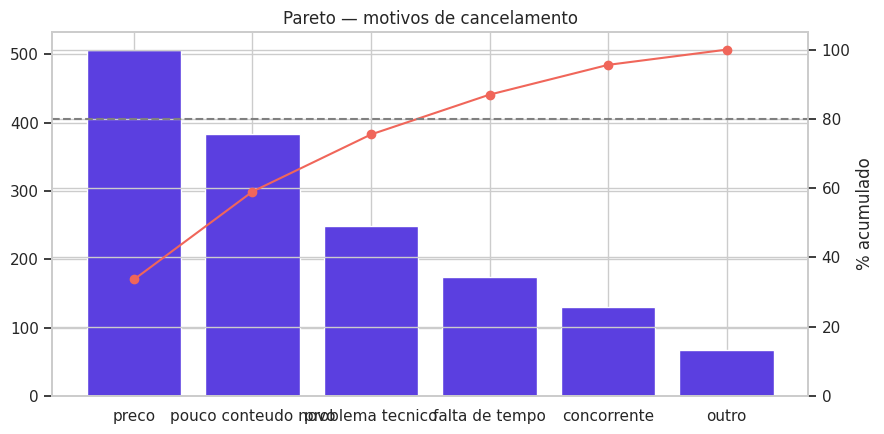

In [85]:
import unicodedata

def sem_acento(s):
    return (unicodedata.normalize('NFKD', str(s))
            .encode('ascii', 'ignore').decode('ascii').strip().lower())

# Normalize the 'motivo_cancelamento' column in df_filtrado as requested
df_filtrado['motivo_cancelamento'] = df_filtrado['motivo_cancelamento'].apply(sem_acento)

print("Valor contagens da coluna 'motivo_cancelamento' após normalização:")
display(df_filtrado['motivo_cancelamento'].value_counts())

# só churners, motivo padronizado (remove acento/caixa p/ unificar "preço"/"preco")
motivos = df_filtrado.loc[df_filtrado['churn'] == 1, 'motivo_cancelamento']
motivos = motivos[motivos != '']

pareto = motivos.value_counts().to_frame('qtd')
pareto['%'] = (pareto['qtd'] / pareto['qtd'].sum() * 100).round(1)
pareto['acumulado_%'] = pareto['%'].cumsum().round(1)
display(pareto)

vitais = pareto[pareto['acumulado_%'] <= 80].index.tolist()
print(f"Poucos vitais (~80% dos cancelamentos): {vitais}")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(pareto.index, pareto['qtd'], color='#5B3FE0')
ax2 = ax.twinx()
ax2.plot(pareto.index, pareto['acumulado_%'], color='#F0665A', marker='o')
ax2.axhline(80, color='gray', linestyle='--'); ax2.set_ylim(0, 105)
ax2.set_ylabel('% acumulado')
ax.set_title('Pareto — motivos de cancelamento')
plt.xticks(rotation=30, ha='right'); plt.tight_layout(); plt.show()

##Framework 4 — Funil de onboarding
Usa um dataset próprio `(funil_eventos.csv)`, com uma linha por evento de cada cliente. Independe dos outros frameworks.

In [87]:
caminho_pasta = '/content/drive/MyDrive/Pós_graduação/Módulo_3'
caminho_arquivo = os.path.join(caminho_pasta, 'funil_eventos.csv')
fn = pd.read_csv(caminho_arquivo).drop_duplicates()
fn

,cliente_id,etapa
0,2165,assistiu_1a_aula
1,3269,criou_conta
2,4589,criou_conta
3,5228,visitou_site
4,4620,assistiu_1a_aula
...,...,...
12881,3327,visitou_site
12882,1268,renovou
12883,5151,visitou_site
12884,4248,visitou_site


,usuarios,conv_da_etapa_anterior_%,conv_do_topo_%
etapa,,,
visitou_site,5000,NaN,100.0
criou_conta,3377,67.5,67.5
assistiu_1a_aula,2698,79.9,54.0
assinou_plano,1066,39.5,21.3
renovou,695,65.2,13.9


Maior gargalo: entrar em 'assinou_plano' (39.5% da etapa anterior)


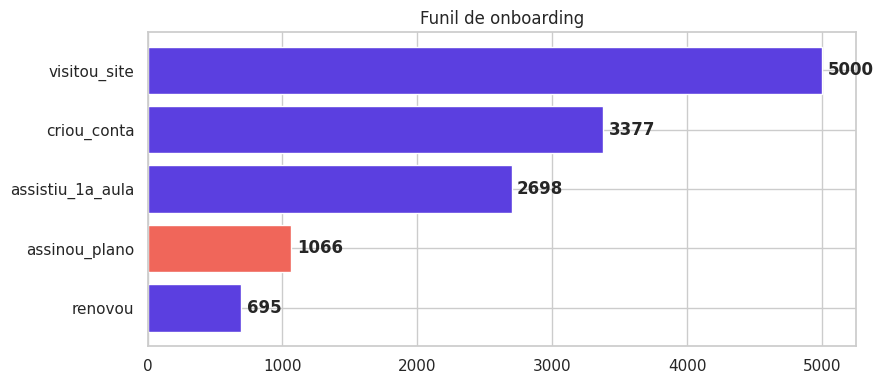

In [88]:
# padroniza a escrita da etapa (unifica "assinou_plano"/"Assinou_Plano"/"assinou plano")
fn['etapa'] = fn['etapa'].astype(str).str.strip().str.lower().str.replace(' ', '_')

ordem = ['visitou_site', 'criou_conta', 'assistiu_1a_aula', 'assinou_plano', 'renovou']
funil = fn.groupby('etapa')['cliente_id'].nunique().reindex(ordem).to_frame('usuarios')
funil['conv_da_etapa_anterior_%'] = (funil['usuarios'] / funil['usuarios'].shift(1) * 100).round(1)
funil['conv_do_topo_%'] = (funil['usuarios'] / funil['usuarios'].iloc[0] * 100).round(1)
display(funil)

gargalo = funil['conv_da_etapa_anterior_%'].idxmin()
print(f"Maior gargalo: entrar em '{gargalo}' ({funil['conv_da_etapa_anterior_%'].min()}% da etapa anterior)")

plt.figure(figsize=(9, 4))
cores = ['#5B3FE0' if e != gargalo else '#F0665A' for e in ordem]
plt.barh(range(len(ordem))[::-1], funil['usuarios'], color=cores)
plt.yticks(range(len(ordem))[::-1], ordem)
for i, v in enumerate(funil['usuarios']):
    plt.text(v + 40, len(ordem)-1-i, f"{int(v)}", va='center', fontweight='bold')
plt.title('Funil de onboarding'); plt.tight_layout(); plt.show()